<a href="https://colab.research.google.com/github/LeilyCandela22/CodigoTesis_LeilyCandela_UNAD/blob/main/Codigo_Tesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

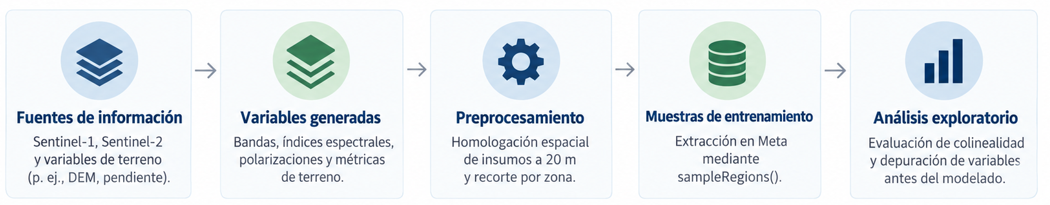

#**Presentado por:**
##**Leily Johanna Candela Becerra**

####**Requisitos Previos**

*   Contar con una cuenta de Google registrada en Google Earth Engine.
*   Tener habilitada la API de Earth Engine y un proyecto asociado en Google Cloud.
*  Trabajar en un entorno con soporte para Python 3 (por ejemplo, Jupyter Notebook local, VSCode, o Google Colab).
*   Instalación de librerías
*   Importación de librerías (Si alguna librería no está instalada, el entorno devolverá un error de importación y será necesario instalarla)
*   Autenticación en Google Earth Engine
*   Inicialización del proyecto
*   Verificación del inicio de sesión


#**1. Importación de librerias y conexiones a servicios GEE**

## 1.1. Importar bibliotecas y hacer la autenticación en GEE

***Cargar las librerías necesarias***

*   Conectarse a la API de Google Earth Engine y manejar colecciones de imágenes (ee, geemap).
*   Realizar operaciones numéricas y tabulares (numpy, pandas).
*   Generar visualizaciones y gráficos de apoyo (matplotlib.pyplot).
*   Disponer de herramientas básicas de modelado estadístico (sklearn), útiles cuando se requieran regresiones o ajustes simples asociados a los productos derivados de las imágenes.

***Autenticar e inicializar la sesión con Google Earth Engine***
> Asociar el trabajo a un proyecto específico en la consola de Google Cloud. La autenticación se realiza mediante el método ee.Authenticate(), que abre un flujo de autorización para vincular la cuenta de usuario con el script. Posteriormente, ee.Initialize(project='...') establece el contexto de ejecución, permitiendo que todas las consultas y operaciones sobre imágenes satelitales se ejecuten dentro del proyecto de GEE seleccionado.

In [ ]:
# =========================
# Python estándar
# =========================
import os
import time
import math
from collections import Counter
from textwrap import fill
import joblib
# =========================
# Google Earth Engine (GEE) y Colab
# =========================
import ee
from ee import batch
from ee.batch import Export
import geemap
from google.colab import auth
# =========================
# Ciencia de datos / Analítica Espacial
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
# =========================
# Machine Learning y modelado
# =========================
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, RandomizedSearchCV
# =========================
# Estadística y métricas de rendimiento
# =========================
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
print("¡Librerias Importadas!")

¡Librerias Importadas!


##1.2. Autenticación servicios Google Earth Engine (GEE)

Se realiza los procesos de autenticación y conexión con GEE usando las credenciales de una cuenta específica, asociada a un proyecto.

In [ ]:
import ee

ee.Authenticate(auth_mode='notebook')

True

In [ ]:
ee.Initialize(project='proyectogradolc')

print('Conexión correcta con Google Earth Engine')

Conexión correcta con Google Earth Engine


#**2. Carga de datos de entrada**

## 2.1. Carga las áreas de interés (AOI) de validación y entrenamiento<br>
**Área de interés de entrenamiento (Meta) y de Prueba o validación (Cesar)**<br>
Con las librerías de GEE se hace el cargue de las 2 áreas de interés (AOI):
<br>*  Meta es el área de entrenamiento. (Visualización en color azul)
<br>*  Cesar es el área de Prueba o validación. (Visualización en color rojo)
<br>Luego se genera un mapa interactivo con la librería geemap centrado en Colombia y añade ambas capas para su visualización. <br>

In [ ]:
# Cargar el shapefile del AOI Meta como un ee.FeatureCollection
asset_id = "projects/proyectogradolc/assets/AreaEntrenamiento"
AOI_Meta = ee.FeatureCollection(asset_id)

# Cargar el shapefile del AOI Cesar como un ee.FeatureCollection
asset_id = "projects/proyectogradolc/assets/AreaValidacion"
AOI_Cesar = ee.FeatureCollection(asset_id)


In [ ]:
# Importar geemap
import geemap

# Crear mapa interactivo usando un mapa base diferente a OpenStreetMap
Map = geemap.Map(
    center=[4, -73],
    zoom=6,
    basemap="Esri.WorldImagery"
)

# Parámetros de visualización del AOI Meta
aoi_vis_params_meta = {
    'color': 'blue',
    'width': 2
}

# Parámetros de visualización del AOI Cesar
aoi_vis_params_cesar = {
    'color': 'red',
    'width': 2
}

# Añadir AOI Meta
Map.addLayer(
    AOI_Meta,
    aoi_vis_params_meta,
    "AOI Meta"
)

# Añadir AOI Cesar
Map.addLayer(
    AOI_Cesar,
    aoi_vis_params_cesar,
    "AOI Cesar"
)

# Mostrar el mapa
Map

Map(center=[4, -73], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tran…

## 2.2. Cargar la colección de datos

### 2.2.1. Datos del terreno y morfometría

El código carga un modelo digital de elevación (DEM) desde un asset en Google Earth Engine, calcula la pendiente en grados y la rugosidad como la desviación estándar en una ventana 3x3. Estas tres variables se apilan en una sola imagen con bandas llamadas DEM, Pendiente y Rugosidad. Finalmente, se crea un mapa interactivo centrado en la región y se visualiza el DEM en metros con una paleta de colores que va de azul a rojo.

In [ ]:
# ============================================================
# VARIABLES DEL TERRENO RECORTADAS POR AOI
# META = ENTRENAMIENTO
# CESAR = VALIDACIÓN
# ============================================================

import ee
import geemap


# ------------------------------------------------------------
# CARGAR LOS DEM
# ------------------------------------------------------------

dem_meta = (
    ee.Image('projects/proyectogradolc/assets/MDE_Meta')
    .select([0])
    .rename('DEM')
    .toFloat()
)

dem_cesar = (
    ee.Image('projects/proyectogradolc/assets/MDE_Cesar')
    .select([0])
    .rename('DEM')
    .toFloat()
)


# ------------------------------------------------------------
# RECORTAR CADA DEM CON SU POLÍGONO
# ------------------------------------------------------------

dem_meta = dem_meta.clip(AOI_Meta)

dem_cesar = dem_cesar.clip(AOI_Cesar)


# ------------------------------------------------------------
# CALCULAR PENDIENTE
# ------------------------------------------------------------

pendiente_meta = (
    ee.Terrain.slope(dem_meta)
    .rename('Pendiente')
    .toFloat()
)

pendiente_cesar = (
    ee.Terrain.slope(dem_cesar)
    .rename('Pendiente')
    .toFloat()
)


# ------------------------------------------------------------
# CALCULAR RUGOSIDAD
# Ventana 3x3 píxeles
# ------------------------------------------------------------

kernel_3x3 = ee.Kernel.square(
    radius=1,
    units='pixels'
)

rugosidad_meta = (
    dem_meta.reduceNeighborhood(
        reducer=ee.Reducer.stdDev(),
        kernel=kernel_3x3
    )
    .rename('Rugosidad')
    .toFloat()
)

rugosidad_cesar = (
    dem_cesar.reduceNeighborhood(
        reducer=ee.Reducer.stdDev(),
        kernel=kernel_3x3
    )
    .rename('Rugosidad')
    .toFloat()
)


# ------------------------------------------------------------
# VOLVER A RECORTAR LAS VARIABLES DERIVADAS
# Esto asegura que los bordes no salgan del AOI
# ------------------------------------------------------------

pendiente_meta = pendiente_meta.clip(AOI_Meta)
rugosidad_meta = rugosidad_meta.clip(AOI_Meta)

pendiente_cesar = pendiente_cesar.clip(AOI_Cesar)
rugosidad_cesar = rugosidad_cesar.clip(AOI_Cesar)


# ------------------------------------------------------------
# CREAR STACKS
# ------------------------------------------------------------

dem_terreno_meta = ee.Image.cat([
    dem_meta,
    pendiente_meta,
    rugosidad_meta
]).rename([
    'DEM',
    'Pendiente',
    'Rugosidad'
])


dem_terreno_cesar = ee.Image.cat([
    dem_cesar,
    pendiente_cesar,
    rugosidad_cesar
]).rename([
    'DEM',
    'Pendiente',
    'Rugosidad'
])


# ------------------------------------------------------------
# VISUALIZACIÓN
# ------------------------------------------------------------

vis_dem = {
    'min': 0,
    'max': 4000,
    'palette': [
        '0000FF',
        '00FFFF',
        '00FF00',
        'FFFF00',
        'FFA500',
        'FF0000'
    ]
}

vis_pendiente = {
    'min': 0,
    'max': 60,
    'palette': [
        'FFFFFF',
        'FFFF00',
        'FFA500',
        'FF0000'
    ]
}

vis_rugosidad = {
    'min': 0,
    'max': 100,
    'palette': [
        'FFFFFF',
        'FFFF00',
        'FFA500',
        'FF0000'
    ]
}


# ------------------------------------------------------------
# CREAR MAPA
# ------------------------------------------------------------

Map = geemap.Map(
    center=[6.5, -73.5],
    zoom=6,
    basemap='Esri.WorldImagery'
)


# ------------------------------------------------------------
# AGREGAR CAPAS META
# ------------------------------------------------------------

Map.addLayer(
    dem_meta,
    vis_dem,
    'DEM Meta recortado',
    True
)

Map.addLayer(
    pendiente_meta,
    vis_pendiente,
    'Pendiente Meta',
    False
)

Map.addLayer(
    rugosidad_meta,
    vis_rugosidad,
    'Rugosidad Meta',
    False
)


# ------------------------------------------------------------
# AGREGAR CAPAS CESAR
# ------------------------------------------------------------

Map.addLayer(
    dem_cesar,
    vis_dem,
    'DEM Cesar recortado',
    True
)

Map.addLayer(
    pendiente_cesar,
    vis_pendiente,
    'Pendiente Cesar',
    False
)

Map.addLayer(
    rugosidad_cesar,
    vis_rugosidad,
    'Rugosidad Cesar',
    False
)


# ------------------------------------------------------------
# MOSTRAR LOS POLÍGONOS AOI
# ------------------------------------------------------------

Map.addLayer(
    AOI_Meta.style(
        color='0000FF',
        fillColor='00000000',
        width=2
    ),
    {},
    'AOI Meta',
    True
)

Map.addLayer(
    AOI_Cesar.style(
        color='FF0000',
        fillColor='00000000',
        width=2
    ),
    {},
    'AOI Cesar',
    True
)


# ------------------------------------------------------------
# CENTRAR MAPA
# ------------------------------------------------------------

geometria_total = AOI_Meta.geometry().union(
    AOI_Cesar.geometry(),
    maxError=100
)

Map.centerObject(
    geometria_total,
    6
)


# ------------------------------------------------------------
# MOSTRAR MAPA
# ------------------------------------------------------------

Map

Map(center=[7.961420516460219, -73.19552822343474], controls=(WidgetControl(options=['position', 'transparent_…

### 2.2.2. Cargar las imágenes de Sentinel 1 y cálculo de variables temáticas

Este bloque carga la colección de imágenes satelitales de Sentinel 1 filtrados al área de estudio y con fecha de adquisición el periodo 2020-01-01 hasta el 2023-08-30. El modo de adquisición es IW y las polarizaciones vertical-vertical (VV) y vertical-horizontal(VH).

***Área de Entrenamiento (Meta)***

In [ ]:
# ============================================================
# SENTINEL-1 - ÁREA DE ENTRENAMIENTO (META)
# Promedios mensuales multianuales 2022-2024
# ============================================================

import ee
import geemap

# ------------------------------------------------------------
# Cargar y filtrar Sentinel-1
# ------------------------------------------------------------

S1_meta = ee.ImageCollection('COPERNICUS/S1_GRD') \
    .filterBounds(AOI_Meta) \
    .filterDate('2022-01-01', '2025-01-01') \
    .filter(ee.Filter.eq('instrumentMode', 'IW')) \
    .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING')) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')) \
    .select(['VV', 'VH'])

print("Número de imágenes Sentinel-1 para Meta:", S1_meta.size().getInfo())


# ------------------------------------------------------------
# Calcular variables derivadas
# ------------------------------------------------------------

def agregar_variables_s1_meta(img):
    VV_db = img.select('VV')
    VH_db = img.select('VH')

    # Diferencia VV-VH en dB
    resta_VV_VH = VV_db.subtract(VH_db).rename('Resta_VV_VH')

    # Conversión de dB a escala lineal
    VV_lineal = ee.Image(10).pow(VV_db.divide(10))
    VH_lineal = ee.Image(10).pow(VH_db.divide(10))

    # Ratio VV/VH
    ratio_VV_VH = VV_lineal.divide(VH_lineal).rename('Ratio_VV_VH')

    # Radar Vegetation Index
    RVI = VH_lineal.multiply(4).divide(VV_lineal.add(VH_lineal)).rename('RVI')

    return img.addBands([resta_VV_VH, ratio_VV_VH, RVI]) \
              .select(['VV', 'VH', 'Resta_VV_VH', 'Ratio_VV_VH', 'RVI']) \
              .toFloat()

S1_meta_variables = S1_meta.map(agregar_variables_s1_meta)


# ------------------------------------------------------------
# Crear promedios mensuales multianuales
# ------------------------------------------------------------

meses_meta = ee.List.sequence(1, 12)

def promedio_mensual_meta(m):
    m = ee.Number(m)

    imagenes_mes = S1_meta_variables.filter(ee.Filter.calendarRange(m, m, 'month'))
    promedio = imagenes_mes.mean().clipToCollection(AOI_Meta)

    nombre_mes = m.format('%02d')
    nombres_nuevos = promedio.bandNames().map(
        lambda banda: ee.String(banda).cat('_').cat(nombre_mes)
    )

    return promedio.rename(nombres_nuevos)

imagenes_mensuales_meta = meses_meta.map(promedio_mensual_meta)


# ------------------------------------------------------------
# Crear stack multitemporal
# ------------------------------------------------------------

S1_stack_meta = ee.ImageCollection.fromImages(imagenes_mensuales_meta).toBands()

# Eliminar prefijos generados por toBands()
nombres_meta = S1_stack_meta.bandNames()
nombres_meta_limpios = nombres_meta.map(
    lambda nombre: ee.String(nombre).split('_').slice(1).join('_')
)

S1_variables_meta = S1_stack_meta.rename(nombres_meta_limpios) \
                                  .clipToCollection(AOI_Meta) \
                                  .toFloat()


# ------------------------------------------------------------
# Verificar resultado
# ------------------------------------------------------------

print("\nBandas Sentinel-1 Meta:\n", S1_variables_meta.bandNames().getInfo())
print("\nNúmero total de variables Sentinel-1 Meta:", S1_variables_meta.bandNames().size().getInfo())


# ------------------------------------------------------------
# Visualización
# ------------------------------------------------------------

Map_Meta = geemap.Map(basemap='Esri.WorldImagery')

vis_s1_meta = {
    'bands': ['VV_01'],
    'min': -25,
    'max': 0,
    'palette': ['000000', 'FFFFFF']
}

Map_Meta.addLayer(S1_variables_meta, vis_s1_meta, 'Sentinel-1 VV Enero - Meta', True)
Map_Meta.addLayer(AOI_Meta.style(color='0000FF', fillColor='00000000', width=2), {}, 'Área de entrenamiento - Meta', True)
Map_Meta.centerObject(AOI_Meta, 8)

Map_Meta

Número de imágenes Sentinel-1 para Meta: 85

Bandas Sentinel-1 Meta:
 ['VV_01', 'VH_01', 'Resta_VV_VH_01', 'Ratio_VV_VH_01', 'RVI_01', 'VV_02', 'VH_02', 'Resta_VV_VH_02', 'Ratio_VV_VH_02', 'RVI_02', 'VV_03', 'VH_03', 'Resta_VV_VH_03', 'Ratio_VV_VH_03', 'RVI_03', 'VV_04', 'VH_04', 'Resta_VV_VH_04', 'Ratio_VV_VH_04', 'RVI_04', 'VV_05', 'VH_05', 'Resta_VV_VH_05', 'Ratio_VV_VH_05', 'RVI_05', 'VV_06', 'VH_06', 'Resta_VV_VH_06', 'Ratio_VV_VH_06', 'RVI_06', 'VV_07', 'VH_07', 'Resta_VV_VH_07', 'Ratio_VV_VH_07', 'RVI_07', 'VV_08', 'VH_08', 'Resta_VV_VH_08', 'Ratio_VV_VH_08', 'RVI_08', 'VV_09', 'VH_09', 'Resta_VV_VH_09', 'Ratio_VV_VH_09', 'RVI_09', 'VV_10', 'VH_10', 'Resta_VV_VH_10', 'Ratio_VV_VH_10', 'RVI_10', 'VV_11', 'VH_11', 'Resta_VV_VH_11', 'Ratio_VV_VH_11', 'RVI_11', 'VV_12', 'VH_12', 'Resta_VV_VH_12', 'Ratio_VV_VH_12', 'RVI_12']

Número total de variables Sentinel-1 Meta: 60


Map(center=[4.519071550313455, -72.99548376817451], controls=(WidgetControl(options=['position', 'transparent_…

***Área de Validación (Cesar)***

In [ ]:
# ============================================================
# SENTINEL-1 - ÁREA DE VALIDACIÓN (CESAR)
# Promedios mensuales multianuales 2022-2024
# ============================================================

import ee
import geemap

# ------------------------------------------------------------
# Cargar y filtrar Sentinel-1
# ------------------------------------------------------------

S1_cesar = ee.ImageCollection('COPERNICUS/S1_GRD') \
    .filterBounds(AOI_Cesar) \
    .filterDate('2022-01-01', '2025-01-01') \
    .filter(ee.Filter.eq('instrumentMode', 'IW')) \
    .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING')) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')) \
    .select(['VV', 'VH'])

print("Número de imágenes Sentinel-1 para Cesar:", S1_cesar.size().getInfo())


# ------------------------------------------------------------
# Calcular variables derivadas
# ------------------------------------------------------------

def agregar_variables_s1_cesar(img):
    VV_db = img.select('VV')
    VH_db = img.select('VH')

    # Diferencia VV-VH en dB
    resta_VV_VH = VV_db.subtract(VH_db).rename('Resta_VV_VH')

    # Conversión de dB a escala lineal
    VV_lineal = ee.Image(10).pow(VV_db.divide(10))
    VH_lineal = ee.Image(10).pow(VH_db.divide(10))

    # Ratio VV/VH
    ratio_VV_VH = VV_lineal.divide(VH_lineal).rename('Ratio_VV_VH')

    # Radar Vegetation Index
    RVI = VH_lineal.multiply(4).divide(VV_lineal.add(VH_lineal)).rename('RVI')

    return img.addBands([resta_VV_VH, ratio_VV_VH, RVI]) \
              .select(['VV', 'VH', 'Resta_VV_VH', 'Ratio_VV_VH', 'RVI']) \
              .toFloat()

S1_cesar_variables = S1_cesar.map(agregar_variables_s1_cesar)


# ------------------------------------------------------------
# Crear promedios mensuales multianuales
# ------------------------------------------------------------

meses_cesar = ee.List.sequence(1, 12)

def promedio_mensual_cesar(m):
    m = ee.Number(m)

    imagenes_mes = S1_cesar_variables.filter(ee.Filter.calendarRange(m, m, 'month'))
    promedio = imagenes_mes.mean().clipToCollection(AOI_Cesar)

    nombre_mes = m.format('%02d')
    nombres_nuevos = promedio.bandNames().map(
        lambda banda: ee.String(banda).cat('_').cat(nombre_mes)
    )

    return promedio.rename(nombres_nuevos)

imagenes_mensuales_cesar = meses_cesar.map(promedio_mensual_cesar)


# ------------------------------------------------------------
# Crear stack multitemporal
# ------------------------------------------------------------

S1_stack_cesar = ee.ImageCollection.fromImages(imagenes_mensuales_cesar).toBands()

# Eliminar prefijos generados por toBands()
nombres_cesar = S1_stack_cesar.bandNames()
nombres_cesar_limpios = nombres_cesar.map(
    lambda nombre: ee.String(nombre).split('_').slice(1).join('_')
)

S1_variables_cesar = S1_stack_cesar.rename(nombres_cesar_limpios) \
                                   .clipToCollection(AOI_Cesar) \
                                   .toFloat()


# ------------------------------------------------------------
# Verificar resultado
# ------------------------------------------------------------

print("\nBandas Sentinel-1 Cesar:\n", S1_variables_cesar.bandNames().getInfo())
print("\nNúmero total de variables Sentinel-1 Cesar:", S1_variables_cesar.bandNames().size().getInfo())


# ------------------------------------------------------------
# Visualización
# ------------------------------------------------------------

Map_Cesar = geemap.Map(basemap='Esri.WorldImagery')

vis_s1_cesar = {
    'bands': ['VV_01'],
    'min': -25,
    'max': 0,
    'palette': ['000000', 'FFFFFF']
}

Map_Cesar.addLayer(S1_variables_cesar, vis_s1_cesar, 'Sentinel-1 VV Enero - Cesar', True)
Map_Cesar.addLayer(AOI_Cesar.style(color='FF0000', fillColor='00000000', width=2), {}, 'Área de validación - Cesar', True)
Map_Cesar.centerObject(AOI_Cesar, 8)

Map_Cesar

Número de imágenes Sentinel-1 para Cesar: 167

Bandas Sentinel-1 Cesar:
 ['VV_01', 'VH_01', 'Resta_VV_VH_01', 'Ratio_VV_VH_01', 'RVI_01', 'VV_02', 'VH_02', 'Resta_VV_VH_02', 'Ratio_VV_VH_02', 'RVI_02', 'VV_03', 'VH_03', 'Resta_VV_VH_03', 'Ratio_VV_VH_03', 'RVI_03', 'VV_04', 'VH_04', 'Resta_VV_VH_04', 'Ratio_VV_VH_04', 'RVI_04', 'VV_05', 'VH_05', 'Resta_VV_VH_05', 'Ratio_VV_VH_05', 'RVI_05', 'VV_06', 'VH_06', 'Resta_VV_VH_06', 'Ratio_VV_VH_06', 'RVI_06', 'VV_07', 'VH_07', 'Resta_VV_VH_07', 'Ratio_VV_VH_07', 'RVI_07', 'VV_08', 'VH_08', 'Resta_VV_VH_08', 'Ratio_VV_VH_08', 'RVI_08', 'VV_09', 'VH_09', 'Resta_VV_VH_09', 'Ratio_VV_VH_09', 'RVI_09', 'VV_10', 'VH_10', 'Resta_VV_VH_10', 'Ratio_VV_VH_10', 'RVI_10', 'VV_11', 'VH_11', 'Resta_VV_VH_11', 'Ratio_VV_VH_11', 'RVI_11', 'VV_12', 'VH_12', 'Resta_VV_VH_12', 'Ratio_VV_VH_12', 'RVI_12']

Número total de variables Sentinel-1 Cesar: 60


Map(center=[9.758074137474694, -73.30118849241777], controls=(WidgetControl(options=['position', 'transparent_…

### 2.2.3. Cargar las imágenes de Sentinel 2 y cálculo de variables temáticas

***Área de Entrenamiento (Meta)***

Este bloque define una función para enmascarar nubes en imágenes de Sentinel-2 utilizando la capa de clasificación de nubes (SCL). Luego, carga una colección de imágenes Sentinel-2 armonizadas para el área de interés (AOI_Meta), filtrando por fechas, porcentaje de nubosidad y área, y aplica la función de enmascarado de nubes. Después, calcula un mosaico de imágenes usando la mediana de la colección filtrada. Se configura una visualización con parámetros específicos de bandas (NIR, rojo y verde) y se muestra en un mapa interactivo utilizando geemap. Finalmente, imprime el número de imágenes disponibles después del filtrado.

*   #### Bandas Sentinel 2 Promedio de bandas para el periodo de tiempo y promedio de indices para el periodo de tiempo

In [ ]:
# ============================================================
# SENTINEL-2 - ÁREA DE ENTRENAMIENTO (META)
# Compuesto multitemporal 2022-2024
# ============================================================

import ee
import geemap

# ------------------------------------------------------------
# Función para enmascarar nubes y sombras
# ------------------------------------------------------------

def mask_s2_clouds_meta(image):
    scl = image.select('SCL')
    cloud_mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return image.updateMask(cloud_mask)

# ------------------------------------------------------------
# Cargar y filtrar Sentinel-2
# ------------------------------------------------------------

dataset_S2_meta = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
    .filterDate('2022-01-01', '2025-01-01') \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)) \
    .filterBounds(AOI_Meta) \
    .map(mask_s2_clouds_meta)

print("Número de imágenes Sentinel-2 para Meta:", dataset_S2_meta.size().getInfo())

# ------------------------------------------------------------
# Crear compuesto mediante la mediana
# ------------------------------------------------------------

S2_meta = dataset_S2_meta.median().clipToCollection(AOI_Meta)

print("\nBandas disponibles Sentinel-2 Meta:\n", S2_meta.bandNames().getInfo())

# ------------------------------------------------------------
# Seleccionar bandas de interés
# ------------------------------------------------------------

bands_of_interest_meta = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']

S2_variables_meta = S2_meta.select(bands_of_interest_meta).toFloat()

print("\nBandas seleccionadas Sentinel-2 Meta:\n", S2_variables_meta.bandNames().getInfo())
print("\nNúmero total de bandas Sentinel-2 Meta:", S2_variables_meta.bandNames().size().getInfo())

# ------------------------------------------------------------
# Visualización
# ------------------------------------------------------------

Map_Meta_S2 = geemap.Map(basemap='Esri.WorldImagery')

vis_s2_meta = {
    'bands': ['B4', 'B3', 'B2'],
    'min': 0,
    'max': 3000,
    'gamma': 1.2
}

Map_Meta_S2.addLayer(S2_variables_meta, vis_s2_meta, 'Sentinel-2 RGB - Meta', True)
Map_Meta_S2.addLayer(AOI_Meta.style(color='0000FF', fillColor='00000000', width=2), {}, 'Área de entrenamiento - Meta', True)
Map_Meta_S2.centerObject(AOI_Meta, 8)

Map_Meta_S2

Número de imágenes Sentinel-2 para Meta: 25

Bandas disponibles Sentinel-2 Meta:
 ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']

Bandas seleccionadas Sentinel-2 Meta:
 ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']

Número total de bandas Sentinel-2 Meta: 10


Map(center=[4.519071550313318, -72.99548376817488], controls=(WidgetControl(options=['position', 'transparent_…

***Área de Validación (Cesar)***

In [ ]:
# ============================================================
# SENTINEL-2 - ÁREA DE VALIDACIÓN (CESAR)
# Compuesto multitemporal 2022-2024
# ============================================================

import ee
import geemap

# ------------------------------------------------------------
# Función para enmascarar nubes y sombras
# ------------------------------------------------------------

def mask_s2_clouds_cesar(image):
    scl = image.select('SCL')
    cloud_mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return image.updateMask(cloud_mask)

# ------------------------------------------------------------
# Cargar y filtrar Sentinel-2
# ------------------------------------------------------------

dataset_S2_cesar = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
    .filterDate('2022-01-01', '2025-01-01') \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)) \
    .filterBounds(AOI_Cesar) \
    .map(mask_s2_clouds_cesar)

print("Número de imágenes Sentinel-2 para Cesar:", dataset_S2_cesar.size().getInfo())

# ------------------------------------------------------------
# Crear compuesto mediante la mediana
# ------------------------------------------------------------

S2_cesar = dataset_S2_cesar.median().clipToCollection(AOI_Cesar)

print("\nBandas disponibles Sentinel-2 Cesar:\n", S2_cesar.bandNames().getInfo())

# ------------------------------------------------------------
# Seleccionar bandas de interés
# ------------------------------------------------------------

bands_of_interest_cesar = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']

S2_variables_cesar = S2_cesar.select(bands_of_interest_cesar).toFloat()

print("\nBandas seleccionadas Sentinel-2 Cesar:\n", S2_variables_cesar.bandNames().getInfo())
print("\nNúmero total de bandas Sentinel-2 Cesar:", S2_variables_cesar.bandNames().size().getInfo())

# ------------------------------------------------------------
# Visualización
# ------------------------------------------------------------

Map_Cesar_S2 = geemap.Map(basemap='Esri.WorldImagery')

vis_s2_cesar = {
    'bands': ['B4', 'B3', 'B2'],
    'min': 0,
    'max': 3000,
    'gamma': 1.2
}

Map_Cesar_S2.addLayer(S2_variables_cesar, vis_s2_cesar, 'Sentinel-2 RGB - Cesar', True)
Map_Cesar_S2.addLayer(AOI_Cesar.style(color='FF0000', fillColor='00000000', width=2), {}, 'Área de validación - Cesar', True)
Map_Cesar_S2.centerObject(AOI_Cesar, 8)

Map_Cesar_S2

Número de imágenes Sentinel-2 para Cesar: 64

Bandas disponibles Sentinel-2 Cesar:
 ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']



Bandas seleccionadas Sentinel-2 Cesar:
 ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']

Número total de bandas Sentinel-2 Cesar: 10


Map(center=[9.758074137474429, -73.30118849241707], controls=(WidgetControl(options=['position', 'transparent_…

*   #### Variables temporales con índices espectrales

Este bloque realiza lo siguiente a partir de imágenes Sentinel 2:

Define una función que calcula el NDVI ((B8 - B4) / (B8 + B4)) y la añade a cada imagen como una nueva banda.

Aplica esa función a la colección Sentinel-2 filtrada y obtiene solo la banda NDVI.

Calcula estadísticos multitemporales del NDVI: media, desviación estándar, mediana, amplitud (máx – mín) y moda (aproximada por redondeo).

Apila todas estas métricas en una sola imagen (S2_ST_NDVI) para análisis posterior.

Visualiza el resultado en un mapa interactivo con capas de falso color, NDVI medio y desviación estándar, usando paletas específicas para cada una.

***Área de Entrenamiento (Meta)***

In [ ]:
# ============================================================
# ÍNDICES TEMPORALES SENTINEL-2 - ENTRENAMIENTO (META)
# NDVI + NDMI + STI
# ============================================================

import ee
import geemap

# ------------------------------------------------------------
# NDVI = (B8 - B4) / (B8 + B4)
# ------------------------------------------------------------

def add_ndvi_meta(image):
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI').toFloat()
    return image.addBands(ndvi)

dataset_S2_meta_NDVI = dataset_S2_meta.map(add_ndvi_meta).select('NDVI')
print("Imágenes NDVI disponibles en Meta:", dataset_S2_meta_NDVI.size().getInfo())

ndvi_mean_meta = dataset_S2_meta_NDVI.mean().rename('NDVI_mean')
ndvi_std_meta = dataset_S2_meta_NDVI.reduce(ee.Reducer.stdDev()).rename('NDVI_stdDev')
ndvi_median_meta = dataset_S2_meta_NDVI.median().rename('NDVI_median')
ndvi_amplitud_meta = dataset_S2_meta_NDVI.max().subtract(dataset_S2_meta_NDVI.min()).rename('NDVI_amplitud')

def redondear_ndvi_meta(img):
    return img.multiply(100).round().divide(100)

ndvi_mode_meta = dataset_S2_meta_NDVI.map(redondear_ndvi_meta) \
    .reduce(ee.Reducer.mode()).rename('NDVI_mode')

S2_ST_NDVI_meta = ndvi_mean_meta \
    .addBands(ndvi_std_meta) \
    .addBands(ndvi_median_meta) \
    .addBands(ndvi_amplitud_meta) \
    .addBands(ndvi_mode_meta) \
    .clipToCollection(AOI_Meta) \
    .toFloat()

print("\nBandas NDVI Meta:\n", S2_ST_NDVI_meta.bandNames().getInfo())


# ------------------------------------------------------------
# NDMI = (B8 - B11) / (B8 + B11)
# ------------------------------------------------------------

def add_ndmi_meta(image):
    ndmi = image.normalizedDifference(['B8', 'B11']).rename('NDMI').toFloat()
    return image.addBands(ndmi)

dataset_S2_meta_NDMI = dataset_S2_meta.map(add_ndmi_meta).select('NDMI')
print("\nImágenes NDMI disponibles en Meta:", dataset_S2_meta_NDMI.size().getInfo())

ndmi_mean_meta = dataset_S2_meta_NDMI.mean().rename('NDMI_mean')
ndmi_std_meta = dataset_S2_meta_NDMI.reduce(ee.Reducer.stdDev()).rename('NDMI_stdDev')
ndmi_median_meta = dataset_S2_meta_NDMI.median().rename('NDMI_median')
ndmi_amplitud_meta = dataset_S2_meta_NDMI.max().subtract(dataset_S2_meta_NDMI.min()).rename('NDMI_amplitud')

def redondear_ndmi_meta(img):
    return img.multiply(100).round().divide(100)

ndmi_mode_meta = dataset_S2_meta_NDMI.map(redondear_ndmi_meta) \
    .reduce(ee.Reducer.mode()).rename('NDMI_mode')

S2_ST_NDMI_meta = ndmi_mean_meta \
    .addBands(ndmi_std_meta) \
    .addBands(ndmi_median_meta) \
    .addBands(ndmi_amplitud_meta) \
    .addBands(ndmi_mode_meta) \
    .clipToCollection(AOI_Meta) \
    .toFloat()

print("\nBandas NDMI Meta:\n", S2_ST_NDMI_meta.bandNames().getInfo())


# ------------------------------------------------------------
# STI = B11 / B12
# ------------------------------------------------------------

def add_sti_meta(image):
    sti = image.select('B11').divide(image.select('B12')).rename('STI').toFloat()
    return image.addBands(sti)

dataset_S2_meta_STI = dataset_S2_meta.map(add_sti_meta).select('STI')
print("\nImágenes STI disponibles en Meta:", dataset_S2_meta_STI.size().getInfo())

sti_mean_meta = dataset_S2_meta_STI.mean().rename('STI_mean')
sti_std_meta = dataset_S2_meta_STI.reduce(ee.Reducer.stdDev()).rename('STI_stdDev')
sti_median_meta = dataset_S2_meta_STI.median().rename('STI_median')
sti_amplitud_meta = dataset_S2_meta_STI.max().subtract(dataset_S2_meta_STI.min()).rename('STI_amplitud')

def redondear_sti_meta(img):
    return img.multiply(100).round().divide(100)

sti_mode_meta = dataset_S2_meta_STI.map(redondear_sti_meta) \
    .reduce(ee.Reducer.mode()).rename('STI_mode')

S2_ST_STI_meta = sti_mean_meta \
    .addBands(sti_std_meta) \
    .addBands(sti_median_meta) \
    .addBands(sti_amplitud_meta) \
    .addBands(sti_mode_meta) \
    .clipToCollection(AOI_Meta) \
    .toFloat()

print("\nBandas STI Meta:\n", S2_ST_STI_meta.bandNames().getInfo())


# ------------------------------------------------------------
# STACK FINAL DE ÍNDICES TEMPORALES - META
# ------------------------------------------------------------

S2_indices_temporales_meta = S2_ST_NDVI_meta \
    .addBands(S2_ST_NDMI_meta) \
    .addBands(S2_ST_STI_meta) \
    .clipToCollection(AOI_Meta) \
    .toFloat()

print("\nBandas totales índices temporales Meta:\n", S2_indices_temporales_meta.bandNames().getInfo())
print("\nNúmero total de variables temporales Meta:", S2_indices_temporales_meta.bandNames().size().getInfo())


# ------------------------------------------------------------
# VISUALIZACIÓN
# ------------------------------------------------------------

Map_Meta_indices = geemap.Map(basemap='Esri.WorldImagery')

vis_ndvi = {'min': -1, 'max': 1, 'palette': ['FF0000', 'FFFF00', '00FF00']}
vis_ndmi = {'min': -1, 'max': 1, 'palette': ['8B4513', 'FFFF00', '0000FF']}
vis_sti = {'min': 0.5, 'max': 2, 'palette': ['0000FF', 'FFFF00', 'FF0000']}

Map_Meta_indices.addLayer(ndvi_mean_meta.clipToCollection(AOI_Meta), vis_ndvi, 'NDVI media - Meta', True)
Map_Meta_indices.addLayer(ndmi_mean_meta.clipToCollection(AOI_Meta), vis_ndmi, 'NDMI media - Meta', False)
Map_Meta_indices.addLayer(sti_mean_meta.clipToCollection(AOI_Meta), vis_sti, 'STI media - Meta', False)
Map_Meta_indices.addLayer(AOI_Meta.style(color='0000FF', fillColor='00000000', width=2), {}, 'Área entrenamiento - Meta', True)

Map_Meta_indices.centerObject(AOI_Meta, 8)
Map_Meta_indices

Imágenes NDVI disponibles en Meta: 25

Bandas NDVI Meta:
 ['NDVI_mean', 'NDVI_stdDev', 'NDVI_median', 'NDVI_amplitud', 'NDVI_mode']

Imágenes NDMI disponibles en Meta: 25

Bandas NDMI Meta:
 ['NDMI_mean', 'NDMI_stdDev', 'NDMI_median', 'NDMI_amplitud', 'NDMI_mode']

Imágenes STI disponibles en Meta: 25

Bandas STI Meta:
 ['STI_mean', 'STI_stdDev', 'STI_median', 'STI_amplitud', 'STI_mode']

Bandas totales índices temporales Meta:
 ['NDVI_mean', 'NDVI_stdDev', 'NDVI_median', 'NDVI_amplitud', 'NDVI_mode', 'NDMI_mean', 'NDMI_stdDev', 'NDMI_median', 'NDMI_amplitud', 'NDMI_mode', 'STI_mean', 'STI_stdDev', 'STI_median', 'STI_amplitud', 'STI_mode']

Número total de variables temporales Meta: 15


Map(center=[4.519071550313455, -72.99548376817451], controls=(WidgetControl(options=['position', 'transparent_…

***Área de Validación (Cesar)***

In [ ]:
# ============================================================
# ÍNDICES TEMPORALES SENTINEL-2 - VALIDACIÓN (CESAR)
# NDVI + NDMI + STI
# ============================================================

import ee
import geemap

# ------------------------------------------------------------
# NDVI = (B8 - B4) / (B8 + B4)
# ------------------------------------------------------------

def add_ndvi_cesar(image):
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI').toFloat()
    return image.addBands(ndvi)

dataset_S2_cesar_NDVI = dataset_S2_cesar.map(add_ndvi_cesar).select('NDVI')
print("Imágenes NDVI disponibles en Cesar:", dataset_S2_cesar_NDVI.size().getInfo())

ndvi_mean_cesar = dataset_S2_cesar_NDVI.mean().rename('NDVI_mean')
ndvi_std_cesar = dataset_S2_cesar_NDVI.reduce(ee.Reducer.stdDev()).rename('NDVI_stdDev')
ndvi_median_cesar = dataset_S2_cesar_NDVI.median().rename('NDVI_median')
ndvi_amplitud_cesar = dataset_S2_cesar_NDVI.max().subtract(dataset_S2_cesar_NDVI.min()).rename('NDVI_amplitud')

def redondear_ndvi_cesar(img):
    return img.multiply(100).round().divide(100)

ndvi_mode_cesar = dataset_S2_cesar_NDVI.map(redondear_ndvi_cesar) \
    .reduce(ee.Reducer.mode()).rename('NDVI_mode')

S2_ST_NDVI_cesar = ndvi_mean_cesar \
    .addBands(ndvi_std_cesar) \
    .addBands(ndvi_median_cesar) \
    .addBands(ndvi_amplitud_cesar) \
    .addBands(ndvi_mode_cesar) \
    .clipToCollection(AOI_Cesar) \
    .toFloat()

print("\nBandas NDVI Cesar:\n", S2_ST_NDVI_cesar.bandNames().getInfo())


# ------------------------------------------------------------
# NDMI = (B8 - B11) / (B8 + B11)
# ------------------------------------------------------------

def add_ndmi_cesar(image):
    ndmi = image.normalizedDifference(['B8', 'B11']).rename('NDMI').toFloat()
    return image.addBands(ndmi)

dataset_S2_cesar_NDMI = dataset_S2_cesar.map(add_ndmi_cesar).select('NDMI')
print("\nImágenes NDMI disponibles en Cesar:", dataset_S2_cesar_NDMI.size().getInfo())

ndmi_mean_cesar = dataset_S2_cesar_NDMI.mean().rename('NDMI_mean')
ndmi_std_cesar = dataset_S2_cesar_NDMI.reduce(ee.Reducer.stdDev()).rename('NDMI_stdDev')
ndmi_median_cesar = dataset_S2_cesar_NDMI.median().rename('NDMI_median')
ndmi_amplitud_cesar = dataset_S2_cesar_NDMI.max().subtract(dataset_S2_cesar_NDMI.min()).rename('NDMI_amplitud')

def redondear_ndmi_cesar(img):
    return img.multiply(100).round().divide(100)

ndmi_mode_cesar = dataset_S2_cesar_NDMI.map(redondear_ndmi_cesar) \
    .reduce(ee.Reducer.mode()).rename('NDMI_mode')

S2_ST_NDMI_cesar = ndmi_mean_cesar \
    .addBands(ndmi_std_cesar) \
    .addBands(ndmi_median_cesar) \
    .addBands(ndmi_amplitud_cesar) \
    .addBands(ndmi_mode_cesar) \
    .clipToCollection(AOI_Cesar) \
    .toFloat()

print("\nBandas NDMI Cesar:\n", S2_ST_NDMI_cesar.bandNames().getInfo())


# ------------------------------------------------------------
# STI = B11 / B12
# ------------------------------------------------------------

def add_sti_cesar(image):
    sti = image.select('B11').divide(image.select('B12')).rename('STI').toFloat()
    return image.addBands(sti)

dataset_S2_cesar_STI = dataset_S2_cesar.map(add_sti_cesar).select('STI')
print("\nImágenes STI disponibles en Cesar:", dataset_S2_cesar_STI.size().getInfo())

sti_mean_cesar = dataset_S2_cesar_STI.mean().rename('STI_mean')
sti_std_cesar = dataset_S2_cesar_STI.reduce(ee.Reducer.stdDev()).rename('STI_stdDev')
sti_median_cesar = dataset_S2_cesar_STI.median().rename('STI_median')
sti_amplitud_cesar = dataset_S2_cesar_STI.max().subtract(dataset_S2_cesar_STI.min()).rename('STI_amplitud')

def redondear_sti_cesar(img):
    return img.multiply(100).round().divide(100)

sti_mode_cesar = dataset_S2_cesar_STI.map(redondear_sti_cesar) \
    .reduce(ee.Reducer.mode()).rename('STI_mode')

S2_ST_STI_cesar = sti_mean_cesar \
    .addBands(sti_std_cesar) \
    .addBands(sti_median_cesar) \
    .addBands(sti_amplitud_cesar) \
    .addBands(sti_mode_cesar) \
    .clipToCollection(AOI_Cesar) \
    .toFloat()

print("\nBandas STI Cesar:\n", S2_ST_STI_cesar.bandNames().getInfo())


# ------------------------------------------------------------
# STACK FINAL DE ÍNDICES TEMPORALES - CESAR
# ------------------------------------------------------------

S2_indices_temporales_cesar = S2_ST_NDVI_cesar \
    .addBands(S2_ST_NDMI_cesar) \
    .addBands(S2_ST_STI_cesar) \
    .clipToCollection(AOI_Cesar) \
    .toFloat()

print("\nBandas totales índices temporales Cesar:\n", S2_indices_temporales_cesar.bandNames().getInfo())
print("\nNúmero total de variables temporales Cesar:", S2_indices_temporales_cesar.bandNames().size().getInfo())


# ------------------------------------------------------------
# VISUALIZACIÓN
# ------------------------------------------------------------

Map_Cesar_indices = geemap.Map(basemap='Esri.WorldImagery')

vis_ndvi = {'min': -1, 'max': 1, 'palette': ['FF0000', 'FFFF00', '00FF00']}
vis_ndmi = {'min': -1, 'max': 1, 'palette': ['8B4513', 'FFFF00', '0000FF']}
vis_sti = {'min': 0.5, 'max': 2, 'palette': ['0000FF', 'FFFF00', 'FF0000']}

Map_Cesar_indices.addLayer(ndvi_mean_cesar.clipToCollection(AOI_Cesar), vis_ndvi, 'NDVI media - Cesar', True)
Map_Cesar_indices.addLayer(ndmi_mean_cesar.clipToCollection(AOI_Cesar), vis_ndmi, 'NDMI media - Cesar', False)
Map_Cesar_indices.addLayer(sti_mean_cesar.clipToCollection(AOI_Cesar), vis_sti, 'STI media - Cesar', False)
Map_Cesar_indices.addLayer(AOI_Cesar.style(color='FF0000', fillColor='00000000', width=2), {}, 'Área validación - Cesar', True)

Map_Cesar_indices.centerObject(AOI_Cesar, 8)
Map_Cesar_indices

Imágenes NDVI disponibles en Cesar: 64

Bandas NDVI Cesar:
 ['NDVI_mean', 'NDVI_stdDev', 'NDVI_median', 'NDVI_amplitud', 'NDVI_mode']

Imágenes NDMI disponibles en Cesar: 64

Bandas NDMI Cesar:
 ['NDMI_mean', 'NDMI_stdDev', 'NDMI_median', 'NDMI_amplitud', 'NDMI_mode']

Imágenes STI disponibles en Cesar: 64

Bandas STI Cesar:
 ['STI_mean', 'STI_stdDev', 'STI_median', 'STI_amplitud', 'STI_mode']

Bandas totales índices temporales Cesar:
 ['NDVI_mean', 'NDVI_stdDev', 'NDVI_median', 'NDVI_amplitud', 'NDVI_mode', 'NDMI_mean', 'NDMI_stdDev', 'NDMI_median', 'NDMI_amplitud', 'NDMI_mode', 'STI_mean', 'STI_stdDev', 'STI_median', 'STI_amplitud', 'STI_mode']

Número total de variables temporales Cesar: 15


Map(center=[9.758074137474429, -73.30118849241707], controls=(WidgetControl(options=['position', 'transparent_…

### 2.2.4. Integración de datos Sentinel 1, Sentinel 2 y DEM

Ajuste de resolución espacial para todos los insumos (10m) y asignación a una grilla de referencia para garantizar el corregistro espacial

**Área de Entrenamiento (Meta)**

Este bloque realiza la homologación espacial de los datos de entrada para garantizar que todas las variables utilizadas en el modelamiento trabajen con una resolución y una proyección compatibles.

*   Paso 0 - Diagnóstico inicial: se imprime la proyección cartográfica y la List item resolución nominal de cada conjunto de datos: variables Sentinel-1, bandas Sentinel-2, variables derivadas del terreno e índices espectrales multitemporales de Sentinel-2.
*   Paso 1 - Definición de la referencia espacial: se utiliza la proyección nativa de la banda B11 de Sentinel-2, cuya resolución espacial es de 20 m, como referencia para la homologación de todos los insumos. Esta resolución se selecciona debido a que varias de las bandas e índices empleados, particularmente aquellos relacionados con las bandas SWIR, presentan resolución nativa de 20 m.
*   Paso 2 - Homologación espacial: los conjuntos de variables Sentinel-1, Sentinel-2, terreno e índices temporales se reproyectan a la misma proyección y grilla espacial definida por la banda B11. De esta manera, todos los predictores quedan espacialmente alineados y con una resolución común de 20 m, evitando generar información artificial mediante el remuestreo de bandas originalmente disponibles a menor resolución espacial.
*   Paso 3 - Verificación final: se consulta nuevamente la resolución nominal de cada conjunto de datos para confirmar que todos los insumos se encuentran homologados a 20 m antes de construir el stack final de variables y realizar el muestreo para el modelo de clasificación.


Para variables continuas, como el DEM, pendiente y rugosidad, puede emplearse un remuestreo bilineal antes de la reproyección, mientras que para variables categóricas debe conservarse el método de vecino más cercano. Además, en las etapas posteriores de muestreo y exportación se mantendrá explícitamente una escala de trabajo de 20 m para asegurar la consistencia espacial del análisis.

In [ ]:
# ============================================================
# HOMOGENEIZACIÓN ESPACIAL - ENTRENAMIENTO (META)
# Resolución común: 20 m
# ============================================================

# ------------------------------------------------------------
# Revisar proyecciones y resoluciones iniciales
# ------------------------------------------------------------

print('Proyección inicial y tamaño de píxel - META:')
print('S1:', S1_variables_meta.projection().getInfo())
print('S2:', S2_variables_meta.projection().getInfo())
print('Terreno:', dem_terreno_meta.projection().getInfo())
print('Índices temporales S2:', S2_indices_temporales_meta.projection().getInfo())

print('\nResolución inicial aproximada (m):')
print('S1:', S1_variables_meta.projection().nominalScale().getInfo())
print('S2:', S2_variables_meta.projection().nominalScale().getInfo())
print('Terreno:', dem_terreno_meta.projection().nominalScale().getInfo())
print('Índices temporales S2:', S2_indices_temporales_meta.projection().nominalScale().getInfo())


# ------------------------------------------------------------
# Definir proyección de referencia Sentinel-2 a 20 m
# Se toma B11 de una imagen Sentinel-2 original
# ------------------------------------------------------------

ref_proj_meta = ee.Image(dataset_S2_meta.first()).select('B11').projection()

print('\nProyección de referencia Meta:')
print(ref_proj_meta.getInfo())
print('Resolución de referencia:', ref_proj_meta.nominalScale().getInfo(), 'm')


# ------------------------------------------------------------
# Reproyectar todos los stacks a la misma grilla
# ------------------------------------------------------------

S1_variables_meta_20m = S1_variables_meta.reproject(ref_proj_meta)
S2_variables_meta_20m = S2_variables_meta.reproject(ref_proj_meta)
dem_terreno_meta_20m = dem_terreno_meta.reproject(ref_proj_meta)
S2_indices_temporales_meta_20m = S2_indices_temporales_meta.reproject(ref_proj_meta)


# ------------------------------------------------------------
# Verificar resolución final
# ------------------------------------------------------------

print('\nResolución final de los datos META (m):')
print('S1:', S1_variables_meta_20m.projection().nominalScale().getInfo())
print('S2:', S2_variables_meta_20m.projection().nominalScale().getInfo())
print('Terreno:', dem_terreno_meta_20m.projection().nominalScale().getInfo())
print('Índices temporales S2:', S2_indices_temporales_meta_20m.projection().nominalScale().getInfo())

Proyección inicial y tamaño de píxel - META:
S1: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}
S2: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}
Terreno: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [0.00011298683773299579, 0, -73.09194707845819, 0, -0.00011299721699819622, 4.7364001807547345]}
Índices temporales S2: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}

Resolución inicial aproximada (m):
S1: 111319.49079327357
S2: 111319.49079327357
Terreno: 12.578214936770964
Índices temporales S2: 111319.49079327357

Proyección de referencia Meta:
{'type': 'Projection', 'crs': 'EPSG:32618', 'transform': [20, 0, 699960, 0, -20, 500040]}
Resolución de referencia: 20 m

Resolución final de los datos META (m):


S1: 20
S2: 20
Terreno: 20
Índices temporales S2: 20


**Área de Validación (Cesar)**

In [ ]:
# ============================================================
# HOMOGENEIZACIÓN ESPACIAL - VALIDACIÓN (CESAR)
# Resolución común: 20 m
# ============================================================

# ------------------------------------------------------------
# Revisar proyecciones y resoluciones iniciales
# ------------------------------------------------------------

print('Proyección inicial y tamaño de píxel - CESAR:')
print('S1:', S1_variables_cesar.projection().getInfo())
print('S2:', S2_variables_cesar.projection().getInfo())
print('Terreno:', dem_terreno_cesar.projection().getInfo())
print('Índices temporales S2:', S2_indices_temporales_cesar.projection().getInfo())

print('\nResolución inicial aproximada (m):')
print('S1:', S1_variables_cesar.projection().nominalScale().getInfo())
print('S2:', S2_variables_cesar.projection().nominalScale().getInfo())
print('Terreno:', dem_terreno_cesar.projection().nominalScale().getInfo())
print('Índices temporales S2:', S2_indices_temporales_cesar.projection().nominalScale().getInfo())


# ------------------------------------------------------------
# Definir proyección de referencia Sentinel-2 a 20 m
# ------------------------------------------------------------

ref_proj_cesar = ee.Image(dataset_S2_cesar.first()).select('B11').projection()

print('\nProyección de referencia Cesar:')
print(ref_proj_cesar.getInfo())
print('Resolución de referencia:', ref_proj_cesar.nominalScale().getInfo(), 'm')


# ------------------------------------------------------------
# Reproyectar todos los stacks a la misma grilla
# ------------------------------------------------------------

S1_variables_cesar_20m = S1_variables_cesar.reproject(ref_proj_cesar)
S2_variables_cesar_20m = S2_variables_cesar.reproject(ref_proj_cesar)
dem_terreno_cesar_20m = dem_terreno_cesar.reproject(ref_proj_cesar)
S2_indices_temporales_cesar_20m = S2_indices_temporales_cesar.reproject(ref_proj_cesar)


# ------------------------------------------------------------
# Verificar resolución final
# ------------------------------------------------------------

print('\nResolución final de los datos CESAR (m):')
print('S1:', S1_variables_cesar_20m.projection().nominalScale().getInfo())
print('S2:', S2_variables_cesar_20m.projection().nominalScale().getInfo())
print('Terreno:', dem_terreno_cesar_20m.projection().nominalScale().getInfo())
print('Índices temporales S2:', S2_indices_temporales_cesar_20m.projection().nominalScale().getInfo())

Proyección inicial y tamaño de píxel - CESAR:
S1: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}
S2: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}
Terreno: {'type': 'Projection', 'crs': 'EPSG:3116', 'transform': [12.61872475216552, 0, 1072889.2778772307, 0, -12.55336197487836, 1587544.132533825]}
Índices temporales S2: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}

Resolución inicial aproximada (m):
S1: 111319.49079327357
S2: 111319.49079327357
Terreno: 12.586000932595349
Índices temporales S2: 111319.49079327357

Proyección de referencia Cesar:
{'type': 'Projection', 'crs': 'EPSG:32618', 'transform': [20, 0, 600000, 0, -20, 1100040]}
Resolución de referencia: 20 m

Resolución final de los datos CESAR (m):
S1: 20
S2: 20
Terreno: 20
Índices temporales S2: 20


**Área de Entrenamiento (Meta)**

Este bloque fusiona todas las variables en un único stack para análisis: usa ee.Image.cat para apilar Sentinel-2, NDVI multitemporal, Sentinel-1, DEM en la imagen apilado_Meta y apilado_Cesar. Luego obtiene la lista de todas las bandas disponibles, imprime el número total de bandas y muestra sus nombres individuales en consola, facilitando la preparación de insumos de entrenamiento para clasificación

In [ ]:
# ============================================================
# STACK FINAL DE VARIABLES - ENTRENAMIENTO (META)
# ============================================================

apilado_meta = ee.Image.cat([
    S1_variables_meta_20m,
    S2_variables_meta_20m,
    dem_terreno_meta_20m,
    S2_indices_temporales_meta_20m
]).clipToCollection(AOI_Meta).toFloat()

# Obtener nombres de bandas
bandas_meta = apilado_meta.bandNames().getInfo()

# Verificar número y nombres de variables
print("Número total de bandas en el stack de entrenamiento Meta:", len(bandas_meta))
print("\nBandas individuales en el stack de entrenamiento Meta:")
for banda in bandas_meta:
    print("-", banda)

Número total de bandas en el stack de entrenamiento Meta: 88

Bandas individuales en el stack de entrenamiento Meta:
- VV_01
- VH_01
- Resta_VV_VH_01
- Ratio_VV_VH_01
- RVI_01
- VV_02
- VH_02
- Resta_VV_VH_02
- Ratio_VV_VH_02
- RVI_02
- VV_03
- VH_03
- Resta_VV_VH_03
- Ratio_VV_VH_03
- RVI_03
- VV_04
- VH_04
- Resta_VV_VH_04
- Ratio_VV_VH_04
- RVI_04
- VV_05
- VH_05
- Resta_VV_VH_05
- Ratio_VV_VH_05
- RVI_05
- VV_06
- VH_06
- Resta_VV_VH_06
- Ratio_VV_VH_06
- RVI_06
- VV_07
- VH_07
- Resta_VV_VH_07
- Ratio_VV_VH_07
- RVI_07
- VV_08
- VH_08
- Resta_VV_VH_08
- Ratio_VV_VH_08
- RVI_08
- VV_09
- VH_09
- Resta_VV_VH_09
- Ratio_VV_VH_09
- RVI_09
- VV_10
- VH_10
- Resta_VV_VH_10
- Ratio_VV_VH_10
- RVI_10
- VV_11
- VH_11
- Resta_VV_VH_11
- Ratio_VV_VH_11
- RVI_11
- VV_12
- VH_12
- Resta_VV_VH_12
- Ratio_VV_VH_12
- RVI_12
- B2
- B3
- B4
- B5
- B6
- B7
- B8
- B8A
- B11
- B12
- DEM
- Pendiente
- Rugosidad
- NDVI_mean
- NDVI_stdDev
- NDVI_median
- NDVI_amplitud
- NDVI_mode
- NDMI_mean
- NDMI_stdDe

**Área de Validación (Cesar)**

In [ ]:
# ============================================================
# STACK FINAL DE VARIABLES - VALIDACIÓN (CESAR)
# ============================================================

apilado_cesar = ee.Image.cat([
    S1_variables_cesar_20m,
    S2_variables_cesar_20m,
    dem_terreno_cesar_20m,
    S2_indices_temporales_cesar_20m
]).clipToCollection(AOI_Cesar).toFloat()

# Obtener nombres de bandas
bandas_cesar = apilado_cesar.bandNames().getInfo()

# Verificar número y nombres de variables
print("Número total de bandas en el stack de validación Cesar:", len(bandas_cesar))
print("\nBandas individuales en el stack de validación Cesar:")
for banda in bandas_cesar:
    print("-", banda)

Número total de bandas en el stack de validación Cesar: 88

Bandas individuales en el stack de validación Cesar:
- VV_01
- VH_01
- Resta_VV_VH_01
- Ratio_VV_VH_01
- RVI_01
- VV_02
- VH_02
- Resta_VV_VH_02
- Ratio_VV_VH_02
- RVI_02
- VV_03
- VH_03
- Resta_VV_VH_03
- Ratio_VV_VH_03
- RVI_03
- VV_04
- VH_04
- Resta_VV_VH_04
- Ratio_VV_VH_04
- RVI_04
- VV_05
- VH_05
- Resta_VV_VH_05
- Ratio_VV_VH_05
- RVI_05
- VV_06
- VH_06
- Resta_VV_VH_06
- Ratio_VV_VH_06
- RVI_06
- VV_07
- VH_07
- Resta_VV_VH_07
- Ratio_VV_VH_07
- RVI_07
- VV_08
- VH_08
- Resta_VV_VH_08
- Ratio_VV_VH_08
- RVI_08
- VV_09
- VH_09
- Resta_VV_VH_09
- Ratio_VV_VH_09
- RVI_09
- VV_10
- VH_10
- Resta_VV_VH_10
- Ratio_VV_VH_10
- RVI_10
- VV_11
- VH_11
- Resta_VV_VH_11
- Ratio_VV_VH_11
- RVI_11
- VV_12
- VH_12
- Resta_VV_VH_12
- Ratio_VV_VH_12
- RVI_12
- B2
- B3
- B4
- B5
- B6
- B7
- B8
- B8A
- B11
- B12
- DEM
- Pendiente
- Rugosidad
- NDVI_mean
- NDVI_stdDev
- NDVI_median
- NDVI_amplitud
- NDVI_mode
- NDMI_mean
- NDMI_stdDev
- 

#**3. Análisis de correlación y colinealidad entre variables**

## 3.1. Carga de muestras de entrenamiento

In [ ]:
# =============================================================
# CARGA DE MUESTRAS DE ENTRENAMIENTO - META
# =============================================================

import ee
import geemap
import pandas as pd
import numpy as np

# Asset de muestras de entrenamiento (Corregido con proyectogradolc)
asset_id_entrenamiento = (
    'projects/proyectogradolc/assets/MuestrasEntrenamiento'
)

training_samples = ee.FeatureCollection(
    asset_id_entrenamiento
)

# ------------------------------------------------------------
# Resumen de las muestras originales
# ------------------------------------------------------------

features_entrenamiento = (
    training_samples
    .getInfo()['features']
)

atributos_entrenamiento = [
    feature['properties']
    for feature in features_entrenamiento
]

df_entrenamiento = pd.DataFrame(
    atributos_entrenamiento
)

# Resumen por clase
class_summary_entrenamiento = (
    df_entrenamiento
    .groupby(
        ['Classvalue', 'Classname']
    )
    .size()
    .reset_index(name='Total')
)

print("Cantidad de polígonos por clase - ENTRENAMIENTO:")
print(
    class_summary_entrenamiento
    .to_string(index=False)
)

print(
    "\nTotal de polígonos de entrenamiento:",
    len(df_entrenamiento)
)

Cantidad de polígonos por clase - ENTRENAMIENTO:
 Classvalue                              Classname  Total
          1 Cultivos Permanentes - Palma de Aceite     50
          2                    Superficies de Agua     49
          3                  Territorios Agricolas    116
          4          Bosques y áreas seminaturales     85
          5           Territorios Artificializados     61

Total de polígonos de entrenamiento: 361


## 3.2. Crear un identificador único para cada polígono

Necesitamos conservar el polígono del cual procede cada píxel. Esto no interviene todavía en la selección de variables, pero después nos permitirá hacer una validación cruzada por grupos, evitando que píxeles de un mismo polígono aparezcan simultáneamente en entrenamiento y validación.

In [ ]:
# ============================================================
# IDENTIFICADOR ÚNICO DE POLÍGONOS
# ============================================================

n_poligonos = training_samples.size()

lista_poligonos = training_samples.toList(
    n_poligonos
)

indices = ee.List.sequence(
    0,
    n_poligonos.subtract(1)
)

def asignar_poly_id(i):

    i = ee.Number(i)

    feature = ee.Feature(
        lista_poligonos.get(i)
    )

    return feature.set(
        'poly_id',
        i.toInt()
    )

training_samples_id = ee.FeatureCollection(
    indices.map(asignar_poly_id)
)

print(
    "Número de polígonos:",
    training_samples_id.size().getInfo()
)

print(
    "Número de poly_id distintos:",
    training_samples_id
    .aggregate_count_distinct('poly_id')
    .getInfo()
)

Número de polígonos: 361
Número de poly_id distintos: 361


## 3.3. Extraer los píxeles de entrenamiento

Ahora extraemos del stack de Meta todos los predictores a 20 m, conservando Classvalue, Classname y poly_id.

Este bloque retira aproximadamente una franja de 20 m del borde para reducir los píxeles mixtos

In [ ]:
# ============================================================
# MUESTREO DE ENTRENAMIENTO
# ELIMINAR BORDE DE LOS POLÍGONOS
# ============================================================

def crear_interior_meta(feature):

    geom_interior = (
        feature
        .geometry()
        .buffer(-20)
    )

    return (
        ee.Feature(geom_interior)
        .copyProperties(feature)
        .set(
            'area_interior',
            geom_interior.area()
        )
    )


training_poligonos_interior = (
    training_samples_id
    .map(crear_interior_meta)
    .filter(
        ee.Filter.gt(
            'area_interior',
            0
        )
    )
)

print(
    "Polígonos originales:",
    training_samples_id.size().getInfo()
)

print(
    "Polígonos con área interior válida:",
    training_poligonos_interior.size().getInfo()
)

Polígonos originales: 361
Polígonos con área interior válida: 330


In [ ]:
# ============================================================
# MUESTREO DE ENTRENAMIENTO
# MÁXIMO 30 PÍXELES INTERIORES POR POLÍGONO
# ============================================================

N_PIXELES_POLIGONO = 30


def muestrear_poligono_meta(feature):

    muestras = (
        apilado_meta
        .sample(
            region=feature.geometry(),
            scale=20,
            numPixels=N_PIXELES_POLIGONO,
            seed=42,
            geometries=False,
            tileScale=4
        )
    )

    muestras = muestras.map(
        lambda pixel:
            pixel.set({
                'Classvalue': feature.get('Classvalue'),
                'Classname': feature.get('Classname'),
                'poly_id': feature.get('poly_id')
            })
    )

    return muestras


training_data = (
    training_poligonos_interior
    .map(muestrear_poligono_meta)
    .flatten()
)

print(
    "Número total de píxeles de entrenamiento:",
    training_data.size().getInfo()
)

Número total de píxeles de entrenamiento: 7404


## 3.4. Convertir a DataFrame y preparar X, y y grupos

Este bloque convierte los píxeles de Meta a un DataFrame y separa claramente tres elementos: X, que contiene exclusivamente los predictores; y, que representa las cinco clases; y groups, que conserva el polígono de procedencia de cada píxel para la validación espacial posterior.

In [ ]:
# ============================================================
# PREPARACIÓN DEL DATAFRAME
# ============================================================

df_training = geemap.ee_to_df(
    training_data
)

print(
    "Dimensión inicial:",
    df_training.shape
)

# ------------------------------------------------------------
# Predictores
# ------------------------------------------------------------

X = (
    df_training[bandas_meta]
    .copy()
    .apply(
        pd.to_numeric,
        errors='coerce'
    )
)

# ------------------------------------------------------------
# Clase
# ------------------------------------------------------------

y = pd.to_numeric(
    df_training['Classvalue'],
    errors='coerce'
)

# ------------------------------------------------------------
# Identificador espacial
# ------------------------------------------------------------

groups = df_training['poly_id'].copy()

# ------------------------------------------------------------
# Reemplazar infinitos
# ------------------------------------------------------------

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

# ------------------------------------------------------------
# Eliminar únicamente observaciones inválidas
# Manteniendo alineados X, y y groups
# ------------------------------------------------------------

mask_validos = (
    X.notna().all(axis=1)
    & y.notna()
    & groups.notna()
)

X = X.loc[mask_validos].copy()

y = (
    y.loc[mask_validos]
    .astype(int)
)

groups = (
    groups.loc[mask_validos]
)

print(
    "\nObservaciones válidas:",
    X.shape[0]
)

print(
    "Variables iniciales:",
    X.shape[1]
)

print("\nDistribución de clases:")
print(
    y.value_counts()
    .sort_index()
)

print(
    "\nNúmero de polígonos:",
    groups.nunique()
)

Dimensión inicial: (7404, 91)

Observaciones válidas: 7404
Variables iniciales: 88

Distribución de clases:
Classvalue
1    1538
2     194
3    3058
4    2023
5     591
Name: count, dtype: int64

Número de polígonos: 319


## 3.5. Eliminar variables constantes

Una variable sin variación no aporta información al modelo y además puede producir problemas numéricos en correlación y VIF. Por ello se eliminan únicamente aquellas columnas que presentan un único valor.

In [ ]:
# ============================================================
# ELIMINACIÓN DE VARIABLES CONSTANTES
# ============================================================

columnas_constantes = [
    columna
    for columna in X.columns
    if X[columna].nunique() <= 1
]

if columnas_constantes:

    print(
        "Variables constantes eliminadas:",
        columnas_constantes
    )

    X = X.drop(
        columns=columnas_constantes
    )

else:

    print(
        "No se encontraron variables constantes."
    )

print(
    "\nVariables disponibles:",
    X.shape[1]
)

No se encontraron variables constantes.

Variables disponibles: 88


## 3.6. Correlación de Pearson

Pearson nos permitirá detectar dependencias lineales fuertes entre predictores. No normalizamos las variables previamente porque el coeficiente de Pearson es invariante frente a transformaciones lineales de escala

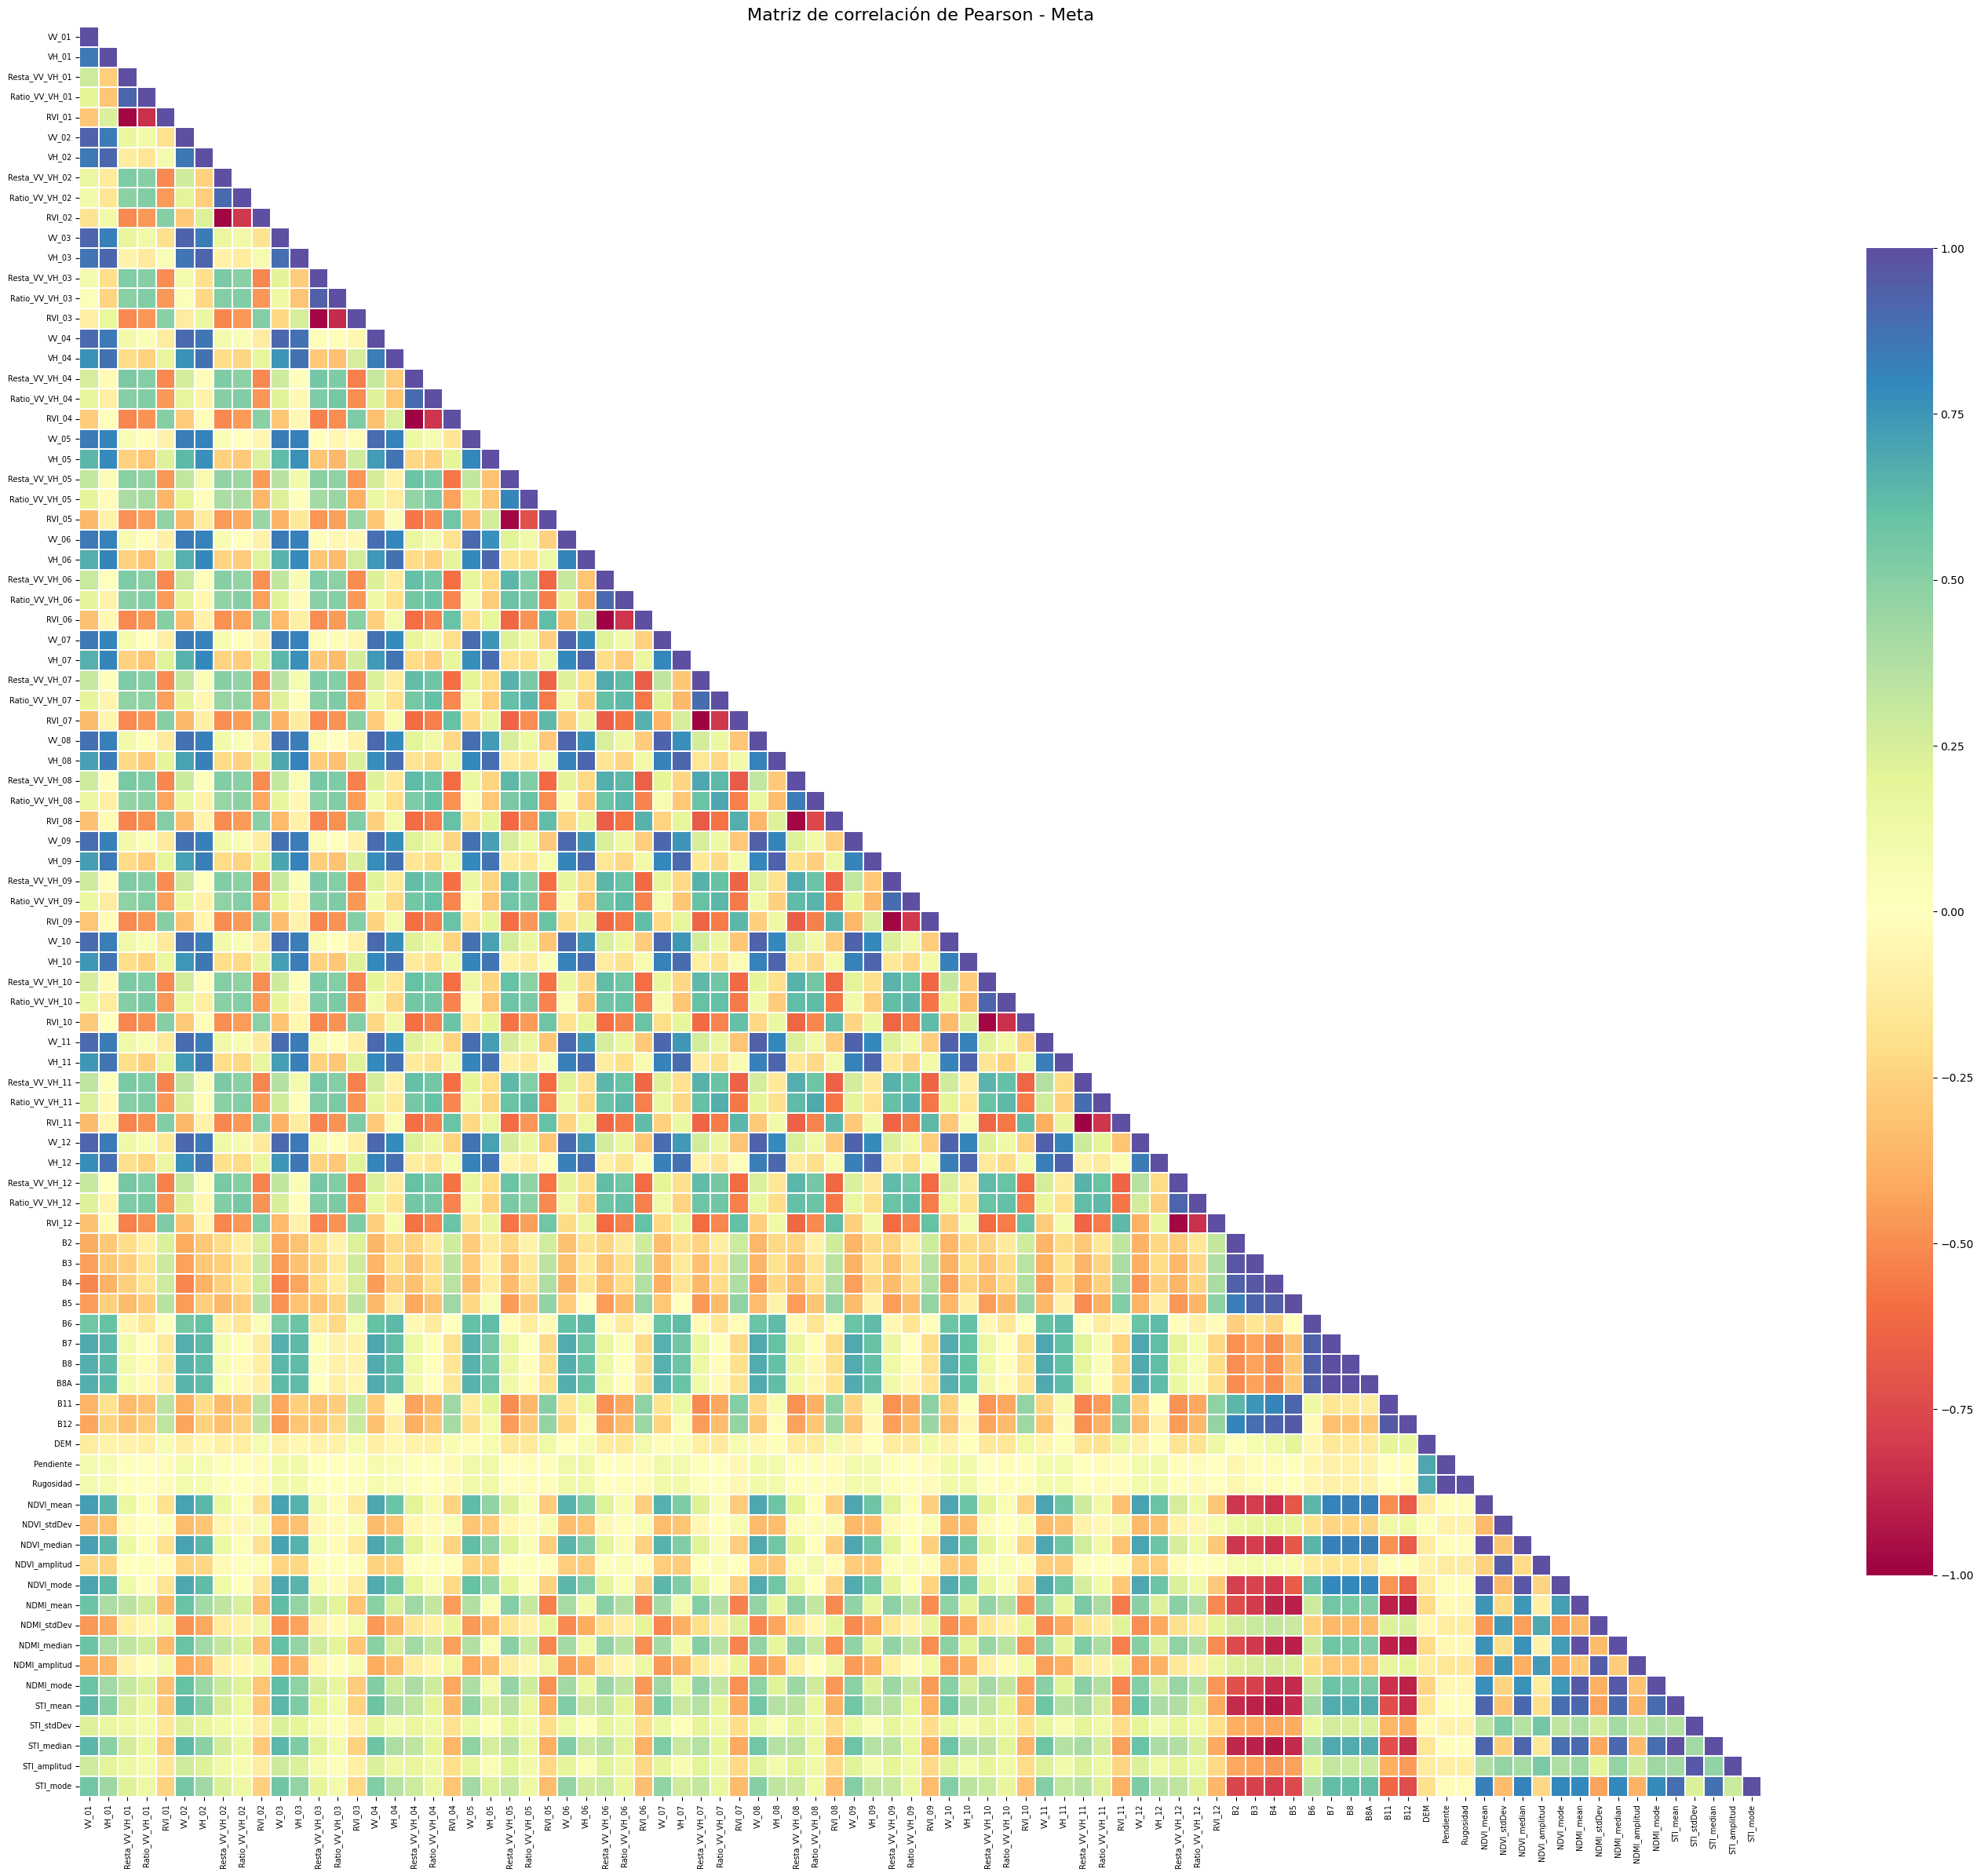

In [ ]:
# ============================================================
# CORRELACIÓN DE PEARSON
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

corr_pearson = X.corr(
    method='pearson'
)

# Máscara triangular
mask = np.triu(
    np.ones_like(
        corr_pearson,
        dtype=bool
    ),
    k=1
)

plt.figure(
    figsize=(28, 24)
)

sns.heatmap(
    corr_pearson,
    mask=mask,
    annot=False,
    cmap='Spectral',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.2,
    cbar_kws={
        'shrink': 0.75
    }
)

plt.title(
    'Matriz de correlación de Pearson - Meta',
    fontsize=16
)

plt.xticks(
    rotation=90,
    fontsize=7
)

plt.yticks(
    rotation=0,
    fontsize=7
)

plt.tight_layout()
plt.show()

## 3.7. Correlación de Spearman

Spearman complementa Pearson porque permite identificar relaciones monotónicas, aunque no sean estrictamente lineales. Esto resulta útil en variables espectrales, índices y respuestas radar que pueden mantener relaciones sistemáticas de naturaleza no lineal.

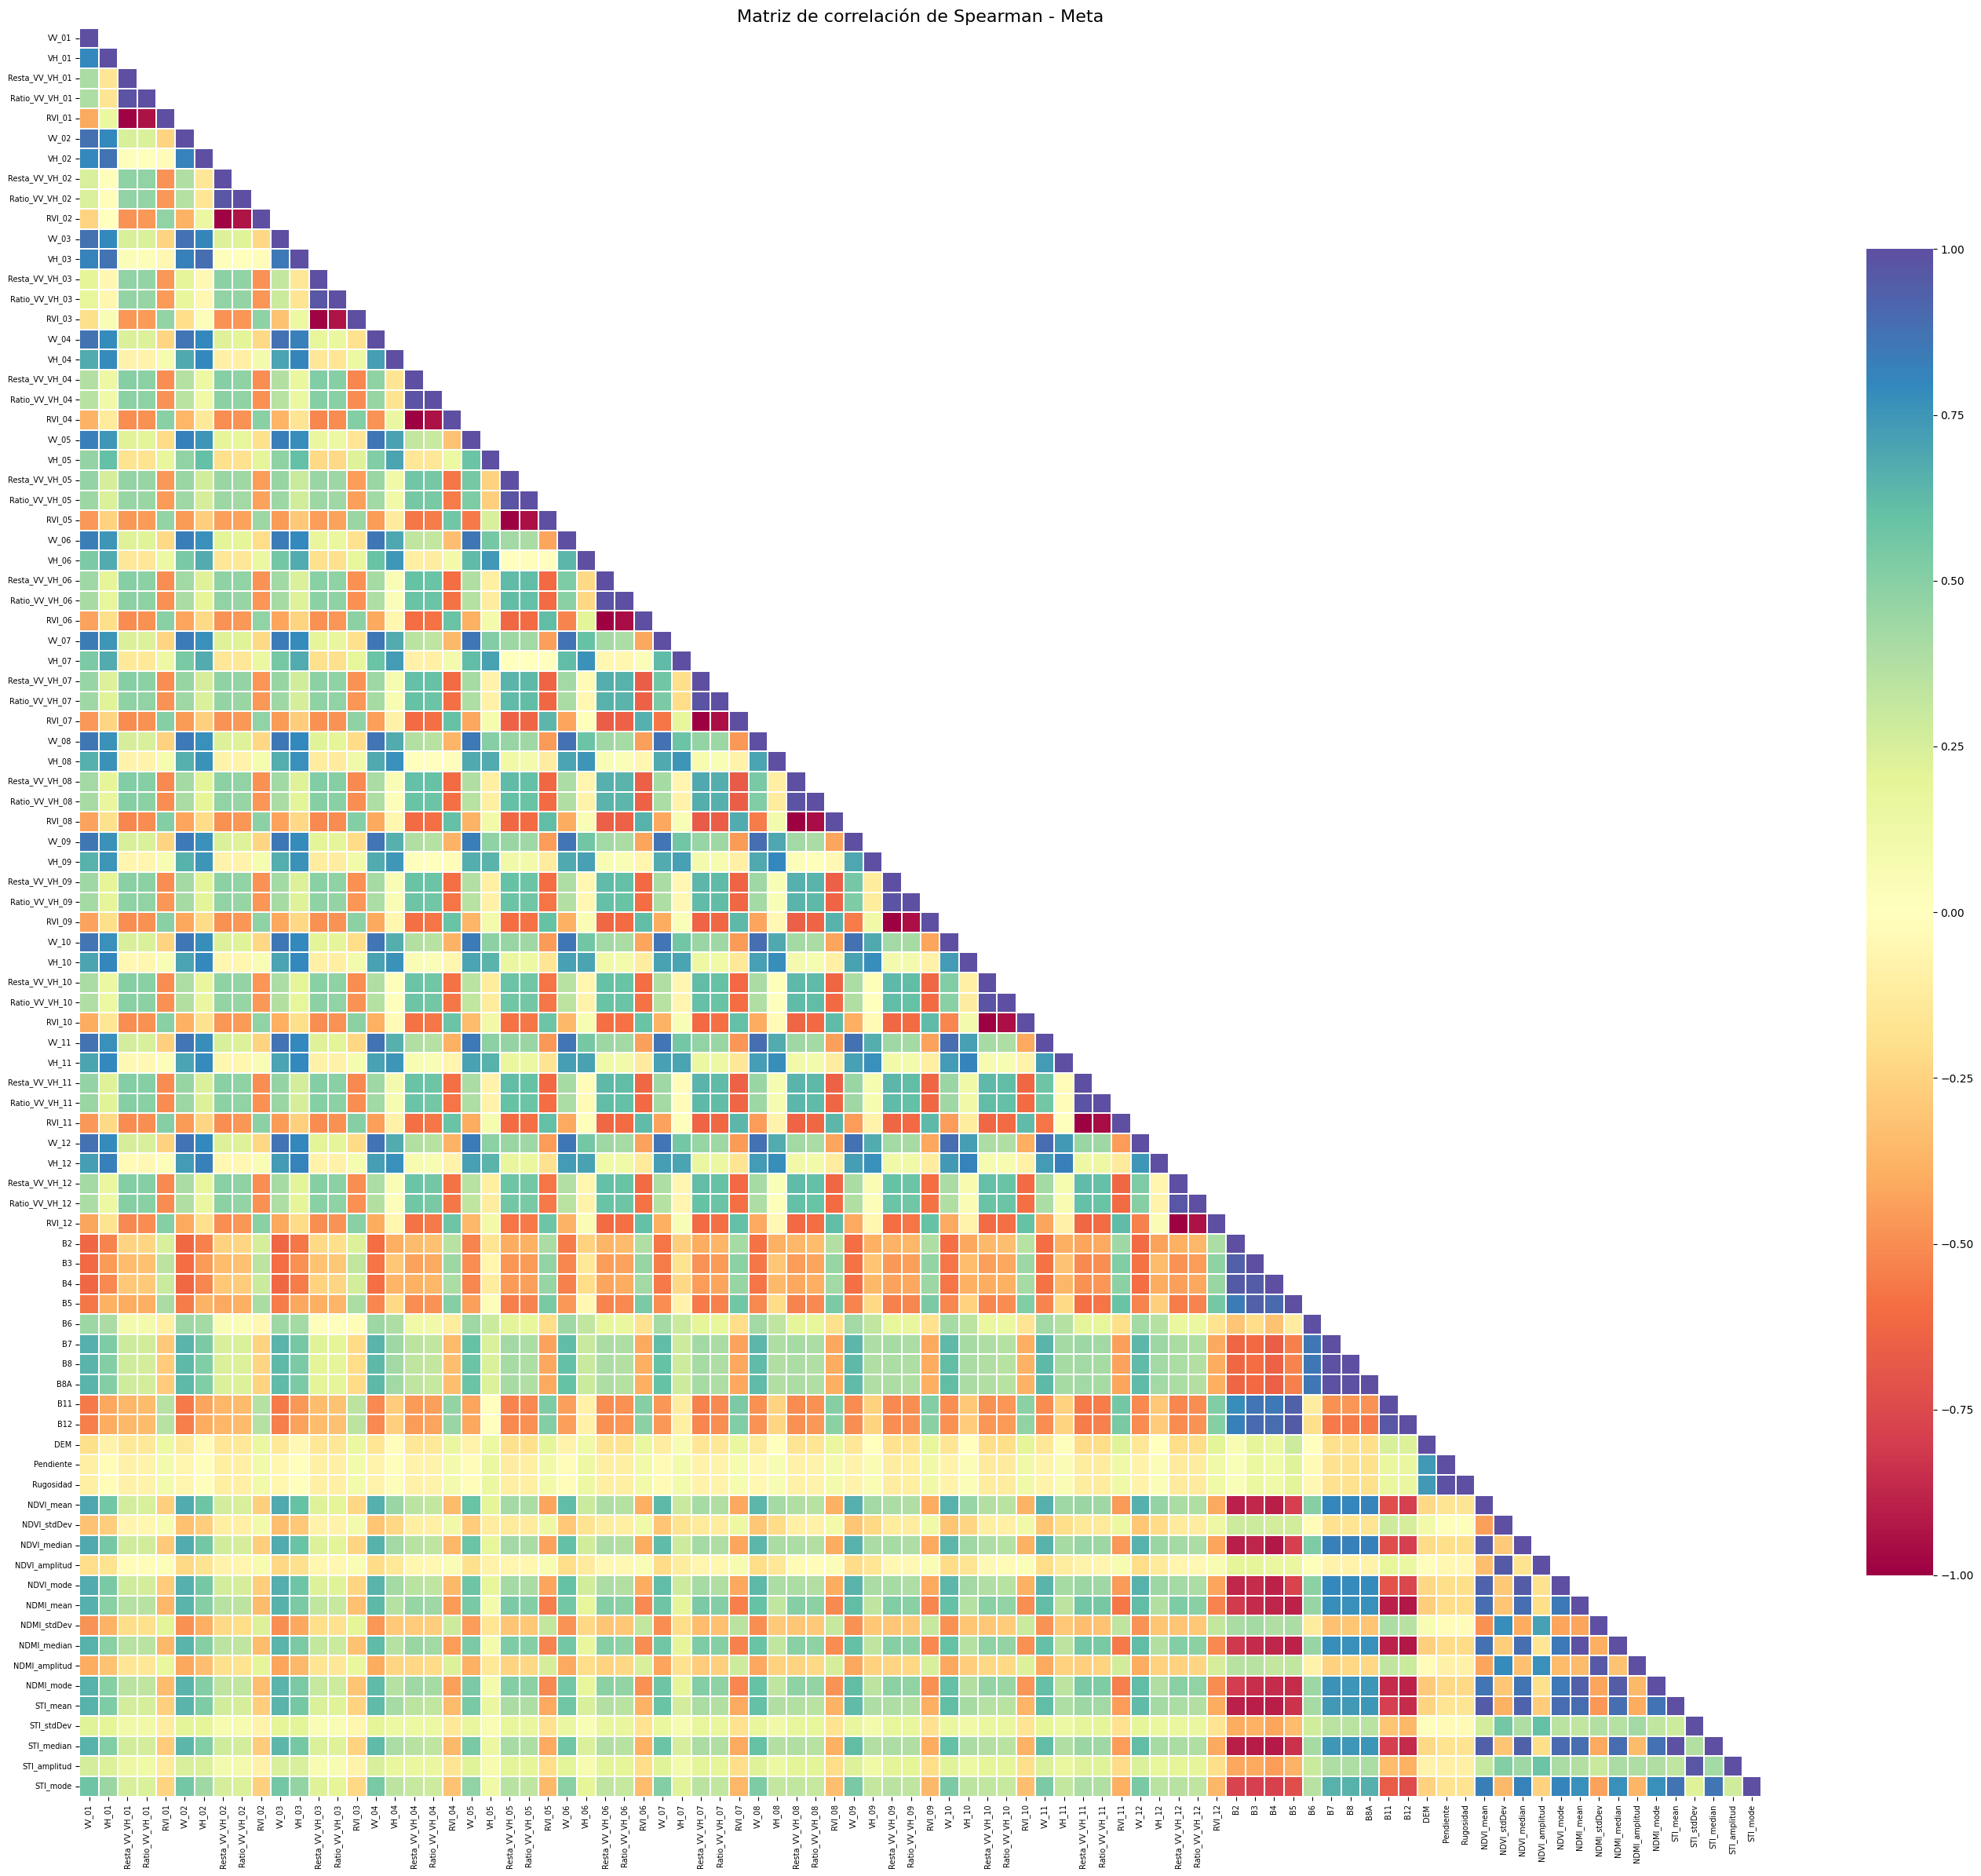

In [ ]:
# ============================================================
# CORRELACIÓN DE SPEARMAN
# ============================================================

corr_spearman = X.corr(
    method='spearman'
)

mask_spearman = np.triu(
    np.ones_like(
        corr_spearman,
        dtype=bool
    ),
    k=1
)

plt.figure(
    figsize=(28, 24)
)

sns.heatmap(
    corr_spearman,
    mask=mask_spearman,
    annot=False,
    cmap='Spectral',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.2,
    cbar_kws={
        'shrink': 0.75
    }
)

plt.title(
    'Matriz de correlación de Spearman - Meta',
    fontsize=16
)

plt.xticks(
    rotation=90,
    fontsize=7
)

plt.yticks(
    rotation=0,
    fontsize=7
)

plt.tight_layout()
plt.show()

## 3.8. Integrar Pearson y Spearman

Una pareja será considerada candidata a redundancia cuando Pearson o Spearman presenten una asociación absoluta elevada.

In [ ]:
# ============================================================
# IDENTIFICACIÓN DE PARES REDUNDANTES
# PEARSON + SPEARMAN
# ============================================================

UMBRAL_CORR = 0.90

pares_redundantes = []

columnas = X.columns.tolist()

for i in range(len(columnas)):

    for j in range(i):

        var1 = columnas[i]
        var2 = columnas[j]

        pearson = corr_pearson.loc[
            var1,
            var2
        ]

        spearman = corr_spearman.loc[
            var1,
            var2
        ]

        if (
            abs(pearson) >= UMBRAL_CORR
            or
            abs(spearman) >= UMBRAL_CORR
        ):

            pares_redundantes.append({
                'Variable_1': var1,
                'Variable_2': var2,
                'Pearson': pearson,
                'Spearman': spearman,
                'Max_abs': max(
                    abs(pearson),
                    abs(spearman)
                )
            })

pares_corr_df = pd.DataFrame(
    pares_redundantes
)

if not pares_corr_df.empty:

    pares_corr_df = (
        pares_corr_df
        .sort_values(
            'Max_abs',
            ascending=False
        )
        .reset_index(drop=True)
    )

print(
    "Número de pares potencialmente redundantes:",
    len(pares_corr_df)
)

display(
    pares_corr_df.head(30)
)

Número de pares potencialmente redundantes: 131


,Variable_1,Variable_2,Pearson,Spearman,Max_abs
0,NDVI_median,NDVI_mean,0.995983,0.964540,0.995983
1,NDMI_median,NDMI_mean,0.995457,0.990418,0.995457
2,STI_median,STI_mean,0.995135,0.986204,0.995135
3,B8A,B8,0.994395,0.990522,0.994395
4,RVI_07,Resta_VV_VH_07,-0.985026,-0.993676,0.993676
5,RVI_06,Resta_VV_VH_06,-0.985094,-0.993595,0.993595
6,RVI_11,Resta_VV_VH_11,-0.985668,-0.993497,0.993497
7,RVI_08,Resta_VV_VH_08,-0.984040,-0.993454,0.993454
8,B8,B7,0.993332,0.989623,0.993332
9,RVI_05,Resta_VV_VH_05,-0.983909,-0.993205,0.993205


## 3.9 VIF inicial

Ahora analizamos la multicolinealidad conjunta. Mientras Pearson y Spearman evalúan relaciones entre pares, el VIF permite identificar variables que pueden ser explicadas por varias de las demás simultáneamente.

*   VIF < 5       → bajo
*   VIF 5–10      → revisar
*   VIF > 10      → multicolinealidad fuerte
*   VIF inf       → redundancia prácticamente exacta



In [ ]:
# ============================================================
# VIF INICIAL
# ============================================================

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

from statsmodels.api import add_constant

X_vif = add_constant(
    X,
    has_constant='add'
)

vif_valores = []

for i in range(
    1,
    X_vif.shape[1]
):

    try:

        vif = variance_inflation_factor(
            X_vif.values,
            i
        )

    except Exception:

        vif = np.inf

    vif_valores.append(vif)

vif_inicial_df = pd.DataFrame({
    'Variable': X.columns,
    'VIF': vif_valores
})

vif_inicial_df = (
    vif_inicial_df
    .sort_values(
        'VIF',
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "VIF INICIAL:"
)

print(
    vif_inicial_df
    .to_string(index=False)
)

VIF INICIAL:
      Variable          VIF
         VV_05 2.257443e+13
         VH_05 2.246184e+13
         VV_07 2.186213e+13
         VV_01 2.154832e+13
         VV_12 2.149690e+13
         VH_07 2.144571e+13
         VH_01 2.139477e+13
         VV_11 2.134407e+13
         VV_08 2.114366e+13
         VH_03 2.109414e+13
         VV_09 2.085000e+13
         VH_06 2.075392e+13
         VV_06 2.075392e+13
         VV_02 2.061144e+13
         VH_08 2.061144e+13
         VH_09 2.037828e+13
         VH_02 2.037828e+13
         VV_03 2.028648e+13
         VV_10 1.979604e+13
         VH_12 1.966637e+13
         VV_04 1.949610e+13
         VH_11 1.932875e+13
         VH_10 1.924615e+13
         VH_04 1.908305e+13
Resta_VV_VH_05 9.116598e+12
Resta_VV_VH_07 8.602865e+12
Resta_VV_VH_06 7.992191e+12
Resta_VV_VH_09 7.852833e+12
Resta_VV_VH_08 7.724871e+12
Resta_VV_VH_11 6.955366e+12
Resta_VV_VH_10 6.849581e+12
Resta_VV_VH_12 6.736873e+12
Resta_VV_VH_04 6.555458e+12
Resta_VV_VH_01 6.531689e+12
Resta_V

## 3.10 Lambda de Wilks

Ahora calculamos una Lambda de Wilks univariada para cada predictor.

Un valor más pequeño significa que la variable presenta una mayor separación entre las cinco clases. Esto nos permitirá decidir cuál conservar cuando dos predictores sean redundantes.

*  Lambda baja
→ mejor separación entre clases

*  Lambda alta
→ menor capacidad discriminante


Poder_Discriminante = 1 - Lambda

In [ ]:
# ============================================================
# LAMBDA DE WILKS
# CAPACIDAD DISCRIMINANTE
# ============================================================

def calcular_wilks(variable, clases):

    datos = pd.DataFrame({
        'x': variable,
        'clase': clases
    }).dropna()

    media_global = (
        datos['x']
        .mean()
    )

    ss_total = (
        (
            datos['x']
            - media_global
        ) ** 2
    ).sum()

    if ss_total == 0:

        return np.nan

    ss_intra = 0

    for clase in (
        datos['clase']
        .unique()
    ):

        valores = (
            datos.loc[
                datos['clase'] == clase,
                'x'
            ]
        )

        ss_intra += (
            (
                valores
                - valores.mean()
            ) ** 2
        ).sum()

    return (
        ss_intra
        / ss_total
    )


wilks_resultados = []

for variable in X.columns:

    lambda_w = calcular_wilks(
        X[variable],
        y
    )

    wilks_resultados.append({
        'Variable': variable,
        'Wilks_Lambda': lambda_w,
        'Poder_Discriminante': (
            1 - lambda_w
            if pd.notna(lambda_w)
            else np.nan
        )
    })

wilks_df = pd.DataFrame(
    wilks_resultados
)

wilks_df = (
    wilks_df
    .sort_values(
        'Wilks_Lambda'
    )
    .reset_index(drop=True)
)

print(
    "Lambda de Wilks por variable:"
)

print(
    wilks_df
    .to_string(
        index=False
    )
)

Lambda de Wilks por variable:
      Variable  Wilks_Lambda  Poder_Discriminante
    STI_median      0.114498             0.885502
      STI_mean      0.124131             0.875869
     NDMI_mean      0.138501             0.861499
     NDVI_mean      0.142287             0.857713
   NDMI_median      0.146532             0.853468
   NDVI_median      0.148926             0.851074
     NDVI_mode      0.183030             0.816970
     NDMI_mode      0.198077             0.801923
           B12      0.227097             0.772903
           B11      0.228893             0.771107
            B4      0.233238             0.766762
            B5      0.234574             0.765426
            B3      0.268400             0.731600
            B2      0.278239             0.721761
      STI_mode      0.302671             0.697329
           B8A      0.330581             0.669419
            B7      0.341904             0.658096
            B8      0.345125             0.654875
         VV_11      

## 3.11 Eliminación de variables redundantes

Este es el primer punto donde realmente eliminamos variables.

Los pares se recorren comenzando por las asociaciones más fuertes. Si ambas variables siguen disponibles, se conserva la que tenga menor Lambda de Wilks. Si ambas presentan prácticamente la misma Lambda, conservamos la que tenga menor redundancia promedio con el resto del conjunto.

Esto evita eliminar variables únicamente porque estén correlacionadas.

In [ ]:
# ============================================================
# ELIMINACIÓN DE VARIABLES REDUNDANTES
# Pearson/Spearman + Lambda de Wilks
# ============================================================

# ------------------------------------------------------------
# Diccionario Lambda
# ------------------------------------------------------------

wilks_dict = dict(
    zip(
        wilks_df['Variable'],
        wilks_df['Wilks_Lambda']
    )
)

# ------------------------------------------------------------
# Redundancia global
# Promedio Pearson + Spearman absolutos
# ------------------------------------------------------------

redundancia_media = (
    (
        corr_pearson.abs()
        +
        corr_spearman.abs()
    ) / 2
)

np.fill_diagonal(
    redundancia_media.values,
    np.nan
)

redundancia_global = (
    redundancia_media
    .mean()
)

# ------------------------------------------------------------
# Variables disponibles
# ------------------------------------------------------------

variables_activas = set(
    X.columns
)

variables_eliminadas = []

# ------------------------------------------------------------
# Recorrer pares
# ------------------------------------------------------------

for _, fila in (
    pares_corr_df
    .iterrows()
):

    var1 = fila['Variable_1']
    var2 = fila['Variable_2']

    if (
        var1 in variables_activas
        and
        var2 in variables_activas
    ):

        lambda1 = wilks_dict.get(
            var1,
            np.nan
        )

        lambda2 = wilks_dict.get(
            var2,
            np.nan
        )

        # ----------------------------------------
        # Si ambas Lambda están disponibles
        # ----------------------------------------

        if (
            np.isfinite(lambda1)
            and
            np.isfinite(lambda2)
        ):

            if lambda1 < lambda2:

                conservar = var1
                eliminar = var2

            elif lambda2 < lambda1:

                conservar = var2
                eliminar = var1

            else:

                # Lambda prácticamente igual:
                # eliminar la más redundante
                if (
                    redundancia_global[var1]
                    >
                    redundancia_global[var2]
                ):

                    eliminar = var1
                    conservar = var2

                else:

                    eliminar = var2
                    conservar = var1

        else:

            # ----------------------------------------
            # Si Lambda no está disponible
            # ----------------------------------------

            if (
                redundancia_global[var1]
                >
                redundancia_global[var2]
            ):

                eliminar = var1
                conservar = var2

            else:

                eliminar = var2
                conservar = var1

        variables_activas.remove(
            eliminar
        )

        variables_eliminadas.append({
            'Eliminada': eliminar,
            'Conservada': conservar,
            'Pearson': fila['Pearson'],
            'Spearman': fila['Spearman'],
            'Lambda_eliminada': wilks_dict.get(
                eliminar,
                np.nan
            ),
            'Lambda_conservada': wilks_dict.get(
                conservar,
                np.nan
            )
        })

# ------------------------------------------------------------
# Conjunto reducido
# ------------------------------------------------------------

variables_reducidas = [
    variable
    for variable in X.columns
    if variable in variables_activas
]

X_reducido = X[
    variables_reducidas
].copy()

eliminadas_df = pd.DataFrame(
    variables_eliminadas
)

print(
    "Variables iniciales:",
    X.shape[1]
)

print(
    "Variables después de correlación + Wilks:",
    X_reducido.shape[1]
)

print(
    "\nVariables eliminadas:",
    len(variables_eliminadas)
)

display(
    eliminadas_df
)

Variables iniciales: 88
Variables después de correlación + Wilks: 27

Variables eliminadas: 61


,Eliminada,Conservada,Pearson,Spearman,Lambda_eliminada,Lambda_conservada
0,NDVI_median,NDVI_mean,0.995983,0.964540,0.148926,0.142287
1,NDMI_median,NDMI_mean,0.995457,0.990418,0.146532,0.138501
2,STI_mean,STI_median,0.995135,0.986204,0.124131,0.114498
3,B8,B8A,0.994395,0.990522,0.345125,0.330581
4,RVI_07,Resta_VV_VH_07,-0.985026,-0.993676,0.577461,0.573767
...,...,...,...,...,...,...
56,VH_06,VH_08,0.914557,0.750504,0.437803,0.400064
57,VV_04,VV_03,0.913873,0.880250,0.428545,0.364576
58,VV_07,VV_11,0.907796,0.866933,0.399550,0.362156
59,VH_01,VH_03,0.906684,0.874727,0.464245,0.433828


## 3.12 Recalcular VIF después de la reducción

Ahora sí comprobamos si todavía existe multicolinealidad conjunta entre las variables que sobrevivieron.

In [ ]:
# ============================================================
# RECALCULAR VIF DESPUÉS DE LA REDUCCIÓN
# ============================================================

def calcular_vif(df):

    X_aux = add_constant(
        df,
        has_constant='add'
    )

    resultados = []

    for i in range(
        1,
        X_aux.shape[1]
    ):

        try:

            valor = variance_inflation_factor(
                X_aux.values,
                i
            )

        except Exception:

            valor = np.inf

        resultados.append({
            'Variable': df.columns[i - 1],
            'VIF': valor
        })

    return (
        pd.DataFrame(resultados)
        .sort_values(
            'VIF',
            ascending=False
        )
        .reset_index(drop=True)
    )


vif_reducido_df = calcular_vif(
    X_reducido
)

print(
    "VIF después de correlación + Wilks:"
)

print(
    vif_reducido_df
    .to_string(index=False)
)

VIF después de correlación + Wilks:
      Variable          VIF
         VV_05 2.235037e+13
         VH_05 2.224000e+13
         VH_03 2.085000e+13
         VV_03 2.010536e+13
Resta_VV_VH_05 9.025250e+12
Resta_VV_VH_03 4.775821e+12
         VH_04 1.655228e+01
         VV_11 1.576848e+01
         VH_08 1.486952e+01
    STI_median 7.604415e+00
      STI_mode 4.938615e+00
Resta_VV_VH_08 4.415857e+00
Resta_VV_VH_04 3.909231e+00
Resta_VV_VH_11 3.844523e+00
   NDVI_stdDev 3.547464e+00
   NDMI_stdDev 3.080263e+00
           B8A 3.055944e+00
Resta_VV_VH_07 2.771475e+00
  STI_amplitud 2.670118e+00
Resta_VV_VH_09 2.561002e+00
Resta_VV_VH_06 2.551237e+00
Resta_VV_VH_12 2.445238e+00
Resta_VV_VH_10 2.431947e+00
           DEM 2.239762e+00
     Pendiente 2.163259e+00
Resta_VV_VH_01 1.862492e+00
Resta_VV_VH_02 1.829382e+00


## 3.13 Depuración iterativa final por VIF

En vez de detenernos aunque queden VIF enormes, vamos a eliminar iterativamente la variable problemática con peor Lambda de Wilks entre aquellas que presenten VIF > 10.

Esto permite reducir multicolinealidad sin eliminar arbitrariamente la variable de mayor VIF.

In [ ]:
# ============================================================
# DEPURACIÓN ITERATIVA FINAL POR VIF
# ============================================================

UMBRAL_VIF = 10

X_final = X_reducido.copy()

registro_vif = []

iteracion = 1

while True:

    vif_actual = calcular_vif(
        X_final
    )

    max_vif = (
        vif_actual['VIF']
        .max()
    )

    # --------------------------------------------------------
    # Detener cuando todos los VIF sean aceptables
    # --------------------------------------------------------

    if (
        np.isfinite(max_vif)
        and
        max_vif <= UMBRAL_VIF
    ):

        break

    # --------------------------------------------------------
    # Variables con VIF problemático
    # --------------------------------------------------------

    variables_problematicas = (
        vif_actual.loc[
            vif_actual['VIF'] > UMBRAL_VIF,
            'Variable'
        ]
        .tolist()
    )

    # También incluir infinitos
    variables_inf = (
        vif_actual.loc[
            ~np.isfinite(
                vif_actual['VIF']
            ),
            'Variable'
        ]
        .tolist()
    )

    variables_problematicas = list(
        set(
            variables_problematicas
            +
            variables_inf
        )
    )

    if not variables_problematicas:

        break

    # --------------------------------------------------------
    # Entre las problemáticas eliminar aquella con
    # peor capacidad discriminante
    # = Lambda más alta
    # --------------------------------------------------------

    candidatos = pd.DataFrame({
        'Variable': variables_problematicas,
        'Lambda': [
            wilks_dict.get(
                var,
                np.nan
            )
            for var in variables_problematicas
        ]
    })

    candidatos['Lambda'] = (
        candidatos['Lambda']
        .fillna(np.inf)
    )

    variable_eliminar = (
        candidatos
        .sort_values(
            'Lambda',
            ascending=False
        )
        .iloc[0]['Variable']
    )

    vif_variable = (
        vif_actual
        .set_index('Variable')
        .loc[
            variable_eliminar,
            'VIF'
        ]
    )

    registro_vif.append({
        'Iteracion': iteracion,
        'Variable_eliminada': variable_eliminar,
        'VIF': vif_variable,
        'Wilks_Lambda': wilks_dict.get(
            variable_eliminar,
            np.nan
        )
    })

    X_final = X_final.drop(
        columns=variable_eliminar
    )

    iteracion += 1

# ------------------------------------------------------------
# Resultado final
# ------------------------------------------------------------

registro_vif_df = pd.DataFrame(
    registro_vif
)

vif_final_df = calcular_vif(
    X_final
)

print(
    "Número final de variables:",
    X_final.shape[1]
)

print(
    "\nVariables eliminadas durante la depuración VIF:"
)

display(
    registro_vif_df
)

print(
    "\nVIF FINAL:"
)

print(
    vif_final_df
    .to_string(index=False)
)

Número final de variables: 22

Variables eliminadas durante la depuración VIF:


,Iteracion,Variable_eliminada,VIF,Wilks_Lambda
0,1,Resta_VV_VH_03,4.775821e+12,0.759025
1,2,Resta_VV_VH_05,9.025250e+12,0.607277
2,3,VH_04,1.654868e+01,0.509767
3,4,VH_08,1.462502e+01,0.400064
4,5,VV_03,1.193048e+01,0.364576



VIF FINAL:
      Variable      VIF
         VV_11 9.773600
         VV_05 7.720204
         VH_05 7.616309
    STI_median 7.528122
         VH_03 5.315388
      STI_mode 4.935110
   NDVI_stdDev 3.488519
Resta_VV_VH_11 3.363582
           B8A 3.003547
   NDMI_stdDev 2.954958
Resta_VV_VH_08 2.821607
Resta_VV_VH_07 2.746900
  STI_amplitud 2.663751
Resta_VV_VH_09 2.551138
Resta_VV_VH_06 2.541132
Resta_VV_VH_10 2.421479
Resta_VV_VH_12 2.418987
Resta_VV_VH_04 2.242704
           DEM 2.189442
     Pendiente 2.140902
Resta_VV_VH_01 1.851665
Resta_VV_VH_02 1.814331


In [ ]:
# ============================================================
# VARIABLES FINALES DEL MODELO
# ============================================================

variables_finales = (
    X_final
    .columns
    .tolist()
)

print(
    "Variables iniciales:",
    len(bandas_meta)
)

print(
    "Variables finales:",
    len(variables_finales)
)

print(
    "\nLISTA FINAL DE PREDICTORES:"
)

for i, variable in enumerate(
    variables_finales,
    start=1
):

    print(
        f"{i:02d}. {variable}"
    )

Variables iniciales: 88
Variables finales: 22

LISTA FINAL DE PREDICTORES:
01. Resta_VV_VH_01
02. Resta_VV_VH_02
03. VH_03
04. Resta_VV_VH_04
05. VV_05
06. VH_05
07. Resta_VV_VH_06
08. Resta_VV_VH_07
09. Resta_VV_VH_08
10. Resta_VV_VH_09
11. Resta_VV_VH_10
12. VV_11
13. Resta_VV_VH_11
14. Resta_VV_VH_12
15. B8A
16. DEM
17. Pendiente
18. NDVI_stdDev
19. NDMI_stdDev
20. STI_median
21. STI_amplitud
22. STI_mode


In [ ]:
X_modelo = X_final.copy()

y_modelo = y.loc[
    X_modelo.index
].copy()

groups_modelo = groups.loc[
    X_modelo.index
].copy()

## 3.14 Tabla maestra de selección de variables

In [ ]:
# ============================================================
# TABLA MAESTRA DE SELECCIÓN DE VARIABLES
# ============================================================

tabla_variables = pd.DataFrame({
    'Variable': X.columns
})

# Lambda de Wilks
tabla_variables = tabla_variables.merge(
    wilks_df[
        [
            'Variable',
            'Wilks_Lambda',
            'Poder_Discriminante'
        ]
    ],
    on='Variable',
    how='left'
)

# VIF inicial
tabla_variables = tabla_variables.merge(
    vif_inicial_df.rename(
        columns={
            'VIF': 'VIF_Inicial'
        }
    ),
    on='Variable',
    how='left'
)

# VIF final
tabla_variables = tabla_variables.merge(
    vif_final_df.rename(
        columns={
            'VIF': 'VIF_Final'
        }
    ),
    on='Variable',
    how='left'
)

# Estado final
tabla_variables['Estado'] = np.where(
    tabla_variables['Variable']
    .isin(variables_finales),
    'Conservada',
    'Eliminada'
)

tabla_variables = (
    tabla_variables
    .sort_values(
        [
            'Estado',
            'Wilks_Lambda'
        ]
    )
    .reset_index(drop=True)
)

display(
    tabla_variables
)

,Variable,Wilks_Lambda,Poder_Discriminante,VIF_Inicial,VIF_Final,Estado
0,STI_median,0.114498,0.885502,2.978701e+02,7.528122,Conservada
1,STI_mode,0.302671,0.697329,5.067160e+00,4.935110,Conservada
2,B8A,0.330581,0.669419,2.480281e+02,3.003547,Conservada
3,VV_11,0.362156,0.637844,2.134407e+13,9.773600,Conservada
4,VH_03,0.433828,0.566172,2.109414e+13,5.315388,Conservada
...,...,...,...,...,...,...
83,Ratio_VV_VH_03,0.780503,0.219497,5.686909e+01,NaN,Eliminada
84,Ratio_VV_VH_02,0.784455,0.215545,3.023166e+01,NaN,Eliminada
85,STI_stdDev,0.814780,0.185220,3.333524e+01,NaN,Eliminada
86,NDVI_amplitud,0.870255,0.129745,2.525309e+01,NaN,Eliminada


#**4. Entrenamiento del modelo**

## 4.1. Preparar el conjunto final de entrenamiento<br>

Este bloque toma exclusivamente las variables que sobrevivieron al análisis de Pearson, Spearman, VIF y Lambda de Wilks. Además, conserva la clase objetivo (Classvalue) y el identificador del polígono (poly_id). Este último no será utilizado como predictor; servirá únicamente para garantizar una separación espacial adecuada durante la validación cruzada.


In [ ]:
# ============================================================
# PREPARACIÓN DEL CONJUNTO FINAL DE ENTRENAMIENTO
# META
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Predictores finales
# ------------------------------------------------------------

X_modelo = X_final.copy()

# ------------------------------------------------------------
# Variable objetivo
# ------------------------------------------------------------

y_modelo = (
    y.loc[X_modelo.index]
    .copy()
    .astype(int)
)

# ------------------------------------------------------------
# Identificador espacial del polígono
# ------------------------------------------------------------

groups_modelo = (
    groups.loc[X_modelo.index]
    .copy()
)

# ------------------------------------------------------------
# Lista final de variables
# ------------------------------------------------------------

variables_finales = X_modelo.columns.tolist()

# ------------------------------------------------------------
# Verificaciones
# ------------------------------------------------------------

print("CONJUNTO FINAL DE ENTRENAMIENTO")
print("================================")

print("Número de observaciones:", X_modelo.shape[0])
print("Número de variables:", X_modelo.shape[1])
print("Número de polígonos:", groups_modelo.nunique())

print("\nDistribución de píxeles por clase:")
print(
    y_modelo
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Número de polígonos independientes por clase
# ------------------------------------------------------------

df_control = pd.DataFrame({
    'Clase': y_modelo,
    'Poligono': groups_modelo
})

poligonos_por_clase = (
    df_control
    .drop_duplicates()
    .groupby('Clase')['Poligono']
    .nunique()
)

print("\nNúmero de polígonos por clase:")
print(poligonos_por_clase)

print("\nVariables finales:")
for i, var in enumerate(variables_finales, start=1):
    print(f"{i:02d}. {var}")

CONJUNTO FINAL DE ENTRENAMIENTO
Número de observaciones: 7404
Número de variables: 22
Número de polígonos: 319

Distribución de píxeles por clase:
Classvalue
1    1538
2     194
3    3058
4    2023
5     591
Name: count, dtype: int64

Número de polígonos por clase:
Clase
1     50
2     23
3    109
4     84
5     53
Name: Poligono, dtype: int64

Variables finales:
01. Resta_VV_VH_01
02. Resta_VV_VH_02
03. VH_03
04. Resta_VV_VH_04
05. VV_05
06. VH_05
07. Resta_VV_VH_06
08. Resta_VV_VH_07
09. Resta_VV_VH_08
10. Resta_VV_VH_09
11. Resta_VV_VH_10
12. VV_11
13. Resta_VV_VH_11
14. Resta_VV_VH_12
15. B8A
16. DEM
17. Pendiente
18. NDVI_stdDev
19. NDMI_stdDev
20. STI_median
21. STI_amplitud
22. STI_mode


## 4.2 Crear el stack reducido para Google Earth Engine

Este bloque prepara el stack de Meta con exactamente las mismas variables finales utilizadas en Python. Esto será necesario después para entrenar el clasificador equivalente en GEE y clasificar todo el área.

In [ ]:
# ============================================================
# STACK REDUCIDO PARA GOOGLE EARTH ENGINE
# ============================================================

apilado_meta_reducido = (
    apilado_meta
    .select(variables_finales)
)

training_data_reducido = (
    training_data
    .select(
        variables_finales
        + [
            'Classvalue',
            'Classname',
            'poly_id'
        ]
    )
)

# ------------------------------------------------------------
# Verificaciones
# ------------------------------------------------------------

bandas_stack_final = (
    apilado_meta_reducido
    .bandNames()
    .getInfo()
)

print(
    "Número de bandas del stack reducido:",
    len(bandas_stack_final)
)

print(
    "¿El orden coincide exactamente con variables_finales?",
    bandas_stack_final == variables_finales
)

Número de bandas del stack reducido: 22
¿El orden coincide exactamente con variables_finales? True


## 4.3 Comprobar los folds antes de entrenar

Antes de buscar hiperparámetros, conviene comprobar que StratifiedGroupKFold está construyendo folds razonables y que las cinco clases aparecen tanto en entrenamiento como en validación.

In [ ]:
# ============================================================
# COMPROBACIÓN DE LOS FOLDS ESPACIALES
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold

cv_revision = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (idx_train, idx_val) in enumerate(
    cv_revision.split(
        X_modelo,
        y_modelo,
        groups=groups_modelo
    ),
    start=1
):

    y_train_fold = y_modelo.iloc[idx_train]
    y_val_fold = y_modelo.iloc[idx_val]

    groups_train = groups_modelo.iloc[idx_train]
    groups_val = groups_modelo.iloc[idx_val]

    print(f"\nFOLD {fold}")
    print("-" * 30)

    print(
        "Polígonos entrenamiento:",
        groups_train.nunique()
    )

    print(
        "Polígonos validación:",
        groups_val.nunique()
    )

    print(
        "Clases entrenamiento:",
        sorted(y_train_fold.unique())
    )

    print(
        "Clases validación:",
        sorted(y_val_fold.unique())
    )


FOLD 1
------------------------------
Polígonos entrenamiento: 255
Polígonos validación: 64
Clases entrenamiento: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Clases validación: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

FOLD 2
------------------------------
Polígonos entrenamiento: 254
Polígonos validación: 65
Clases entrenamiento: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Clases validación: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

FOLD 3
------------------------------
Polígonos entrenamiento: 255
Polígonos validación: 64
Clases entrenamiento: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Clases validación: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

FOLD 4
------------------------------
Polígonos entrenamiento: 256
Polígonos validación: 63
Clases entrenamiento: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Clases validación: [n

## 4.4 Búsqueda rápida de hiperparámetros

Este bloque realiza la búsqueda utilizando polígonos completos como grupos. Usaremos 3 folds y 8 combinaciones, es decir, solo 24 ajustes, para evitar tiempos excesivos de ejecución. La métrica utilizada será F1 macro, porque da el mismo peso a las cinco clases.

In [ ]:
# ============================================================
# BÚSQUEDA DE HIPERPARÁMETROS
# RANDOM FOREST - META
# VALIDACIÓN POR POLÍGONOS
# ============================================================

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV
)

# ------------------------------------------------------------
# Modelo base
# ------------------------------------------------------------

rf_base = RandomForestClassifier(
    random_state=42,
    bootstrap=True,

    # Evitamos paralelismo doble
    n_jobs=1
)

# ------------------------------------------------------------
# Espacio de búsqueda
# ------------------------------------------------------------

param_grid = {

    'n_estimators': [
        100,
        200,
        300,
        400
    ],

    'max_features': [
        'sqrt',
        0.20,
        0.30,
        0.40
    ],

    'min_samples_leaf': [
        1,
        2,
        3,
        5
    ],

    'max_samples': [
        0.60,
        0.70,
        0.80,
        1.00
    ]
}

# ------------------------------------------------------------
# Validación por grupos durante la búsqueda
# ------------------------------------------------------------

cv_busqueda = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# Randomized Search
#
# 8 combinaciones x 3 folds = 24 ajustes
# ------------------------------------------------------------

search_rf = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=8,
    scoring='f1_macro',
    cv=cv_busqueda,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=False
)

# ------------------------------------------------------------
# Ejecutar búsqueda
# ------------------------------------------------------------

search_rf.fit(
    X_modelo,
    y_modelo,
    groups=groups_modelo
)

# ------------------------------------------------------------
# Resultados
# ------------------------------------------------------------

print("\nMEJORES HIPERPARÁMETROS")
print("=======================")

print(search_rf.best_params_)

print(
    "\nMejor F1 macro promedio durante la búsqueda:"
)

print(
    round(
        search_rf.best_score_,
        4
    )
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits

MEJORES HIPERPARÁMETROS
{'n_estimators': 300, 'min_samples_leaf': 1, 'max_samples': 1.0, 'max_features': 0.4}

Mejor F1 macro promedio durante la búsqueda:
0.9248


## 4.5 Guardar los hiperparámetros seleccionados

Este bloque guarda la configuración ganadora para reutilizarla sin volver a ejecutar la búsqueda.

In [ ]:
# ============================================================
# GUARDAR HIPERPARÁMETROS
# ============================================================

mejores_parametros = search_rf.best_params_

print("Hiperparámetros seleccionados:")

for parametro, valor in mejores_parametros.items():
    print(f"{parametro}: {valor}")

Hiperparámetros seleccionados:
n_estimators: 300
min_samples_leaf: 1
max_samples: 1.0
max_features: 0.4


## 4.6 Validación interna espacial 5-fold - Nivel de Pixel

Ahora evaluamos el mejor modelo con una validación más robusta de cinco folds por polígonos. Las predicciones son fuera de muestra respecto al polígono, por lo que ningún píxel del polígono evaluado se utiliza para entrenar ese fold.

In [ ]:
# ============================================================
# VALIDACIÓN INTERNA ESPACIAL 5-FOLD
# NIVEL DE PÍXEL - META
# ============================================================

from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_predict
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Modelo con los mejores hiperparámetros
# ------------------------------------------------------------

rf_cv = RandomForestClassifier(
    **mejores_parametros,
    random_state=42,
    bootstrap=True,
    n_jobs=-1
)


# ------------------------------------------------------------
# Validación cruzada espacial 5-fold
# ------------------------------------------------------------

cv_final = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# Predicciones out-of-fold
# ------------------------------------------------------------

y_pred_cv = cross_val_predict(
    rf_cv,
    X_modelo,
    y_modelo,
    groups=groups_modelo,
    cv=cv_final,
    n_jobs=-1,
    method='predict'
)

print(
    "Predicciones out-of-fold generadas correctamente."
)

Predicciones out-of-fold generadas correctamente.


### 4.6.1 Métricas globales a nivel de píxel

Aquí calculamos el desempeño global usando todos los píxeles interiores de Meta, pero siempre con predicciones fuera de muestra

In [ ]:
# ============================================================
# MÉTRICAS GLOBALES
# NIVEL DE PÍXEL - META
# ============================================================

accuracy_cv = accuracy_score(
    y_modelo,
    y_pred_cv
)

balanced_accuracy_cv = balanced_accuracy_score(
    y_modelo,
    y_pred_cv
)

f1_macro_cv = f1_score(
    y_modelo,
    y_pred_cv,
    average='macro'
)

kappa_cv = cohen_kappa_score(
    y_modelo,
    y_pred_cv
)

mcc_cv = matthews_corrcoef(
    y_modelo,
    y_pred_cv
)


print(
    "VALIDACIÓN ESPACIAL 5-FOLD - META"
)

print(
    "NIVEL DE PÍXEL"
)

print(
    "=================================="
)

print(
    f"Accuracy          : {accuracy_cv:.4f}"
)

print(
    f"Balanced Accuracy : {balanced_accuracy_cv:.4f}"
)

print(
    f"F1 macro          : {f1_macro_cv:.4f}"
)

print(
    f"Kappa             : {kappa_cv:.4f}"
)

print(
    f"MCC               : {mcc_cv:.4f}"
)

VALIDACIÓN ESPACIAL 5-FOLD - META
NIVEL DE PÍXEL
Accuracy          : 0.9537
Balanced Accuracy : 0.9178
F1 macro          : 0.9300
Kappa             : 0.9340
MCC               : 0.9341


### 4.6.2 Reporte por clase a nivel de píxel

Este bloque permite revisar precisión, recall y F1 para cada una de las cinco clases.

In [ ]:
# ============================================================
# DEFINICIÓN DE CLASES
# ============================================================

clases = [1, 2, 3, 4, 5]

nombres_clases = [
    '1 - Cultivos Permanentes - Palma de Aceite',
    '2 - Superficies de Agua',
    '3 - Territorios Agricolas',
    '4 - Bosques y áreas seminaturales',
    '5 - Territorios Artificializados',
 ]

In [ ]:
# ============================================================
# REPORTE POR CLASE
# NIVEL DE PÍXEL - META
# ============================================================

print(
    classification_report(
        y_modelo,
        y_pred_cv,
        labels=clases,
        target_names=nombres_clases,
        digits=4,
        zero_division=0
    )
)

                                            precision    recall  f1-score   support

1 - Cultivos Permanentes - Palma de Aceite     0.9754    0.9811    0.9783      1538
                   2 - Superficies de Agua     0.9486    0.8557    0.8997       194
                 3 - Territorios Agricolas     0.9522    0.9650    0.9586      3058
         4 - Bosques y áreas seminaturales     0.9591    0.9629    0.9610      2023
          5 - Territorios Artificializados     0.8822    0.8240    0.8521       591

                                  accuracy                         0.9537      7404
                                 macro avg     0.9435    0.9178    0.9300      7404
                              weighted avg     0.9533    0.9537    0.9533      7404



### 4.6.3 Matriz de confusión a nivel de píxel

In [ ]:
# ============================================================
# MATRIZ DE CONFUSIÓN
# NIVEL DE PÍXEL - META
# ============================================================

cm_meta = confusion_matrix(
    y_modelo,
    y_pred_cv,
    labels=clases
)

cm_meta_df = pd.DataFrame(
    cm_meta,
    index=[
        'Real 1 - Cultivos Permanentes - Palma de Aceite',
        'Real 2 - Superficies de Agua',
        'Real 3 - Territorios Agricolas',
        'Real 4 - Bosques y áreas seminaturales',
        'Real 5 - Territorios Artificializados'
    ],
    columns=[
        'Pred 1 - Cultivos Permanentes - Palma de Aceite',
        'Pred 2 - Superficies de Agua',
        'Pred 3 - Territorios Agricolas',
        'Pred 4 - Bosques y áreas seminaturales',
        'Pred 5 - Territorios Artificializados'
    ]
)

display(cm_meta_df)

,Pred 1 - Palma,Pred 2 - Agua,Pred 3 - Áreas agrícolas heterogéneas,Pred 4 - Bosques,Pred 5 - Urbano
Real 1 - Palma,1509,0,9,20,0
Real 2 - Agua,0,166,9,0,19
Real 3 - Áreas agrícolas heterogéneas,4,4,2951,58,41
Real 4 - Bosques,34,0,36,1948,5
Real 5 - Urbano,0,5,94,5,487


### 4.6.4 Matriz de confusión normalizada

Esta visualización permite comparar el rendimiento entre clases aunque tengan distinto número de píxeles.

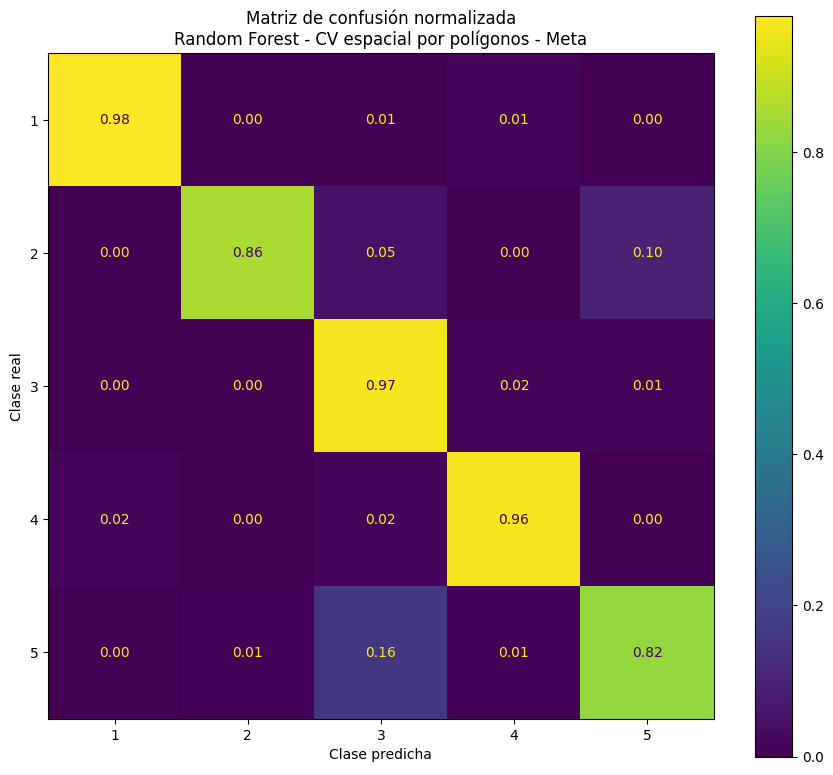

In [ ]:
# ============================================================
# MATRIZ DE CONFUSIÓN NORMALIZADA
# NIVEL DE PÍXEL - META
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 8)
)

ConfusionMatrixDisplay.from_predictions(
    y_modelo,
    y_pred_cv,
    labels=clases,
    display_labels=clases,
    normalize='true',
    values_format='.2f',
    ax=ax
)

plt.title(
    'Matriz de confusión normalizada\n'
    'Random Forest - CV espacial por pixel - Meta'
)

plt.xlabel('Clase predicha')
plt.ylabel('Clase real')

plt.tight_layout()
plt.show()

## 4.7 Validación interna a nivel de polígono

Ahora usamos las mismas predicciones out-of-fold, pero agrupadas por poly_id. Esto no vuelve a entrenar el modelo.

Cada polígono tendrá:

una clase real
+
una clase predicha mediante moda

### 4.7.1 Asociar cada predicción con su polígono

In [ ]:
# ============================================================
# TABLA OUT-OF-FOLD POR POLÍGONO
# META
# ============================================================

df_meta_oof = pd.DataFrame({
    'Classvalue': (
        pd.Series(y_modelo)
        .reset_index(drop=True)
    ),

    'Predicted': (
        pd.Series(y_pred_cv)
        .reset_index(drop=True)
    ),

    'poly_id': (
        pd.Series(groups_modelo)
        .reset_index(drop=True)
    )
})


print(
    "Observaciones OOF Meta:",
    len(df_meta_oof)
)

print(
    "Número de polígonos evaluados:",
    df_meta_oof[
        'poly_id'
    ].nunique()
)

Observaciones OOF Meta: 7404
Número de polígonos evaluados: 319


### 4.7.2 Calcular la moda de las predicciones por polígono

Este bloque asigna a cada polígono la clase que aparece con mayor frecuencia entre sus píxeles interiores.

In [ ]:
# ============================================================
# MODA DE LAS PREDICCIONES POR POLÍGONO
# META
# ============================================================

def moda_predicciones(serie):

    return (
        serie
        .value_counts()
        .idxmax()
    )


df_meta_poly = (
    df_meta_oof
    .groupby(
        'poly_id'
    )
    .agg(
        Classvalue=(
            'Classvalue',
            'first'
        ),

        Predicted_poly=(
            'Predicted',
            moda_predicciones
        ),

        N_pixeles=(
            'Predicted',
            'size'
        )
    )
    .reset_index()
)


print(
    "Número de polígonos evaluados:",
    len(df_meta_poly)
)

display(
    df_meta_poly.head()
)

Número de polígonos evaluados: 319


,poly_id,Classvalue,Predicted_poly,N_pixeles
0,0,1,1,24
1,1,1,1,30
2,2,1,1,30
3,3,1,1,36
4,4,1,1,30


### 4.7.3 Preparar clases reales y predichas por polígono

In [ ]:
# ============================================================
# VARIABLES DE VALIDACIÓN
# NIVEL DE POLÍGONO - META
# ============================================================

y_true_meta_poly = (
    df_meta_poly[
        'Classvalue'
    ]
    .astype(int)
)

y_pred_meta_poly = (
    df_meta_poly[
        'Predicted_poly'
    ]
    .astype(int)
)


print(
    "Distribución real por polígono:"
)

print(
    y_true_meta_poly
    .value_counts()
    .sort_index()
)

print(
    "\nDistribución predicha por polígono:"
)

print(
    y_pred_meta_poly
    .value_counts()
    .sort_index()
)

Distribución real por polígono:
Classvalue
1     50
2     23
3    109
4     84
5     53
Name: count, dtype: int64

Distribución predicha por polígono:
Predicted_poly
1     50
2     20
3    114
4     85
5     50
Name: count, dtype: int64


### 4.7.4 Métricas globales a nivel de polígono

In [ ]:
# ============================================================
# VARIABLES DE VALIDACIÓN
# NIVEL DE POLÍGONO - META
# ============================================================

y_true_meta_poly = (
    df_meta_poly[
        'Classvalue'
    ]
    .astype(int)
)

y_pred_meta_poly = (
    df_meta_poly[
        'Predicted_poly'
    ]
    .astype(int)
)


print(
    "Distribución real por polígono:"
)

print(
    y_true_meta_poly
    .value_counts()
    .sort_index()
)

print(
    "\nDistribución predicha por polígono:"
)

print(
    y_pred_meta_poly
    .value_counts()
    .sort_index()
)

Distribución real por polígono:
Classvalue
1     50
2     23
3    109
4     84
5     53
Name: count, dtype: int64

Distribución predicha por polígono:
Predicted_poly
1     50
2     20
3    114
4     85
5     50
Name: count, dtype: int64


### 4.7.5 Reporte por clase a nivel de polígono

In [ ]:
# ============================================================
# REPORTE POR CLASE
# NIVEL DE POLÍGONO - META
# ============================================================

print(
    classification_report(
        y_true_meta_poly,
        y_pred_meta_poly,
        labels=clases,
        target_names=nombres_clases,
        digits=4,
        zero_division=0
    )
)

                                            precision    recall  f1-score   support

1 - Cultivos Permanentes - Palma de Aceite     1.0000    1.0000    1.0000        50
                   2 - Superficies de Agua     1.0000    0.8696    0.9302        23
                 3 - Territorios Agricolas     0.9386    0.9817    0.9596       109
         4 - Bosques y áreas seminaturales     0.9765    0.9881    0.9822        84
          5 - Territorios Artificializados     0.9600    0.9057    0.9320        53

                                  accuracy                         0.9655       319
                                 macro avg     0.9750    0.9490    0.9608       319
                              weighted avg     0.9662    0.9655    0.9652       319



### 4.7.6 Matriz de confusión a nivel de polígono

In [ ]:
# ============================================================
# MATRIZ DE CONFUSIÓN
# NIVEL DE POLÍGONO - META
# ============================================================

cm_meta_poly = confusion_matrix(
    y_true_meta_poly,
    y_pred_meta_poly,
    labels=clases
)

cm_meta_poly_df = pd.DataFrame(
    cm_meta_poly,
    index=[
        'Real 1 - Cultivos Permanentes - Palma de Aceite',
        'Real 2 - Superficies de Agua',
        'Real 3 - Territorios Agricolas',
        'Real 4 - Bosques y áreas seminaturales',
        'Real 5 - Territorios Artificializados'
    ],
    columns=[
        'Pred 1 - Cultivos Permanentes - Palma de Aceite',
        'Pred 2 - Superficies de Agua',
        'Pred 3 - Territorios Agricolas',
        'Pred 4 - Bosques y áreas seminaturales',
        'Pred 5 - Territorios Artificializados'
    ]
)

display(cm_meta_poly_df)

,Pred 1 - Cultivos Permanentes - Palma de Aceite,Pred 2 - Superficies de Agua,Pred 3 - Territorios Agricolas,Pred 4 - Bosques y áreas seminaturales,Pred 5 - Territorios Artificializados
Real 1 - Cultivos Permanentes - Palma de Aceite,50,0,0,0,0
Real 2 - Superficies de Agua,0,20,1,0,2
Real 3 - Territorios Agricolas,0,0,107,2,0
Real 4 - Bosques y áreas seminaturales,0,0,1,83,0
Real 5 - Territorios Artificializados,0,0,5,0,48


## 4.8 Comparación entre la validación por píxel y por polígono

Este bloque resume ambas escalas de evaluación en una sola tabla.

In [ ]:
# ============================================================
# COMPARACIÓN DE ESCALAS DE VALIDACIÓN
# META
# ============================================================

# Calcular las métricas a nivel de polígono
accuracy_meta_poly = accuracy_score(y_true_meta_poly, y_pred_meta_poly)
balanced_accuracy_meta_poly = balanced_accuracy_score(y_true_meta_poly, y_pred_meta_poly)
f1_macro_meta_poly = f1_score(y_true_meta_poly, y_pred_meta_poly, average='macro')
kappa_meta_poly = cohen_kappa_score(y_true_meta_poly, y_pred_meta_poly)
mcc_meta_poly = matthews_corrcoef(y_true_meta_poly, y_pred_meta_poly)

comparacion_meta = pd.DataFrame({

    'Metrica': [
        'Accuracy',
        'Balanced Accuracy',
        'F1 macro',
        'Kappa',
        'MCC'
    ],

    'Pixel': [
        accuracy_cv,
        balanced_accuracy_cv,
        f1_macro_cv,
        kappa_cv,
        mcc_cv
    ],

    'Poligono': [
        accuracy_meta_poly,
        balanced_accuracy_meta_poly,
        f1_macro_meta_poly,
        kappa_meta_poly,
        mcc_meta_poly
    ]
})


display(
    comparacion_meta
    .round(4)
)

,Metrica,Pixel,Poligono
0,Accuracy,0.9537,0.9655
1,Balanced Accuracy,0.9178,0.9490
2,F1 macro,0.9300,0.9608
3,Kappa,0.9340,0.9542
4,MCC,0.9341,0.9545


## 4.9 Entrenar el Random Forest definitivo en Scikit-learn

Una vez evaluado el modelo, se entrena nuevamente utilizando todas las observaciones válidas de Meta. La validación ya terminó; ahora interesa aprovechar toda la información disponible para construir el modelo final.

In [ ]:
# ============================================================
# ENTRENAMIENTO DEFINITIVO
# RANDOM FOREST - META
# ============================================================

import joblib

rf_final = RandomForestClassifier(
    **mejores_parametros,
    random_state=42,
    bootstrap=True,
    n_jobs=-1
)

# ------------------------------------------------------------
# Entrenar con todas las observaciones
# ------------------------------------------------------------

rf_final.fit(
    X_modelo,
    y_modelo
)

print(
    "Random Forest definitivo entrenado correctamente."
)

print(
    "Observaciones utilizadas:",
    X_modelo.shape[0]
)

print(
    "Variables utilizadas:",
    X_modelo.shape[1]
)

# ------------------------------------------------------------
# Guardar modelo
# ------------------------------------------------------------

joblib.dump(
    rf_final,
    'RandomForest_Meta_Final.joblib'
)

print(
    "\nModelo guardado como:"
)

print(
    "RandomForest_Meta_Final.joblib"
)

Random Forest definitivo entrenado correctamente.
Observaciones utilizadas: 7404
Variables utilizadas: 22

Modelo guardado como:
RandomForest_Meta_Final.joblib


## 4.10 Traducir los hiperparámetros de Scikit-learn a GEE

Scikit-learn y smileRandomForest utilizan parámetros equivalentes con nombres distintos. Este bloque realiza la traducción automáticamente, incluido max_features

In [ ]:
# ============================================================
# TRADUCCIÓN DE HIPERPARÁMETROS
# SCIKIT-LEARN -> GOOGLE EARTH ENGINE
# ============================================================

import math

n_features = len(
    variables_finales
)

max_features_sk = (
    mejores_parametros[
        'max_features'
    ]
)

# ------------------------------------------------------------
# Convertir max_features a variablesPerSplit
# ------------------------------------------------------------

if max_features_sk == 'sqrt':

    variables_per_split = max(
        1,
        int(
            math.sqrt(
                n_features
            )
        )
    )

elif max_features_sk == 'log2':

    variables_per_split = max(
        1,
        int(
            math.log2(
                n_features
            )
        )
    )

elif isinstance(
    max_features_sk,
    float
):

    variables_per_split = max(
        1,
        int(
            max_features_sk
            * n_features
        )
    )

else:

    variables_per_split = int(
        max_features_sk
    )

# ------------------------------------------------------------
# bagFraction
# ------------------------------------------------------------

bag_fraction = float(
    mejores_parametros[
        'max_samples'
    ]
)

# ------------------------------------------------------------
# Parámetros GEE
# ------------------------------------------------------------

FIXED_PARAMS_GEE = {

    'numberOfTrees':
        int(
            mejores_parametros[
                'n_estimators'
            ]
        ),

    'variablesPerSplit':
        int(
            variables_per_split
        ),

    'minLeafPopulation':
        int(
            mejores_parametros[
                'min_samples_leaf'
            ]
        ),

    'bagFraction':
        bag_fraction,

    'seed':
        42
}

print("PARÁMETROS PARA GOOGLE EARTH ENGINE")
print("====================================")

for parametro, valor in FIXED_PARAMS_GEE.items():
    print(
        f"{parametro}: {valor}"
    )

PARÁMETROS PARA GOOGLE EARTH ENGINE
numberOfTrees: 300
variablesPerSplit: 8
minLeafPopulation: 1
bagFraction: 1.0
seed: 42


## 4.11 Entrenar el Random Forest en Google Earth Engine

Aquí entrenamos el clasificador que realmente utilizaremos para generar el mapa ráster.

In [ ]:
# ============================================================
# ENTRENAMIENTO DEL RANDOM FOREST EN GEE
# ============================================================

classifier_meta = (
    ee.Classifier
    .smileRandomForest(

        numberOfTrees=
            FIXED_PARAMS_GEE[
                'numberOfTrees'
            ],

        variablesPerSplit=
            FIXED_PARAMS_GEE[
                'variablesPerSplit'
            ],

        minLeafPopulation=
            FIXED_PARAMS_GEE[
                'minLeafPopulation'
            ],

        bagFraction=
            FIXED_PARAMS_GEE[
                'bagFraction'
            ],

        seed=
            FIXED_PARAMS_GEE[
                'seed'
            ]
    )
    .train(

        features=
            training_data_reducido,

        classProperty=
            'Classvalue',

        inputProperties=
            variables_finales
    )
)

print(
    "Clasificador Random Forest entrenado correctamente en GEE."
)

print(
    "Número de predictores:",
    len(
        variables_finales
    )
)

Clasificador Random Forest entrenado correctamente en GEE.
Número de predictores: 22


## 4.12 Clasificar todo Meta


In [ ]:
# ============================================================
# CLASIFICACIÓN COMPLETA DE META
# ============================================================

clasificacion_meta = (
    apilado_meta_reducido
    .classify(
        classifier_meta
    )
    .rename(
        'Classvalue'
    )
    .clip(
        AOI_Meta
    )
    .toByte()
)

print(
    "Clasificación de Meta generada correctamente."
)

Clasificación de Meta generada correctamente.


In [ ]:
# ============================================================
# VISUALIZACIÓN DE LA CLASIFICACIÓN - META
# Clasificación + AOI + imagen de referencia
# ============================================================

import geemap


# ------------------------------------------------------------
# DEFINIR LAS SEIS CLASES
# ------------------------------------------------------------

clases = [
   '1 - Cultivos Permanentes - Palma de Aceite',
   '2 - Superficies de Agua',
   '3 - Territorios Agricolas',
   '4 - Bosques y áreas seminaturales',
   '5 - Territorios Artificializados',
  ]

nombres_clases = [
    '1 - Cultivos Permanentes - Palma de Aceite',
    '2 - Superficies de Agua',
    '3 - Territorios Agricolas',
    '4 - Bosques y áreas seminaturales',
    '5 - Territorios Artificializados',
  ]


# ------------------------------------------------------------
# PALETA DE COLORES
# ------------------------------------------------------------

palette_clases = [
    'F4A261',  # 1 - Cultivos Permanentes - Palma de Aceite
    '2A9DF4',  # 2 - Superficies de Agua
    'F6D55C',  # 3 - Territorios Agricolas
    '2E8B57',  # 4 - Bosques y áreas seminaturales
    'D62828'   # 5 - Territorios Artificializados
]


vis_clasificacion = {
    'min': 1,
    'max': 5,
    'palette': palette_clases
}


# ------------------------------------------------------------
# CREAR MAPA
# ------------------------------------------------------------

Map_Meta_RF = geemap.Map()

Map_Meta_RF.centerObject(
    AOI_Meta,
    10
)

Map_Meta_RF.add_basemap(
    'SATELLITE'
)


# ------------------------------------------------------------
# IMAGEN RGB DE REFERENCIA
# Opcional: se deja apagada inicialmente
# ------------------------------------------------------------

rgb_meta = apilado_meta.select(
    [
        'B4',
        'B3',
        'B2'
    ]
)

vis_rgb = {
    'min': 0,

    'max': 3000,
    'gamma': 1.2
}

Map_Meta_RF.addLayer(
    rgb_meta.clip(AOI_Meta),
    vis_rgb,
    'RGB Sentinel-2 - Meta',
    False
)


# ------------------------------------------------------------
# CLASIFICACIÓN RANDOM FOREST
# ------------------------------------------------------------

Map_Meta_RF.addLayer(
    clasificacion_meta,
    vis_clasificacion,
    'Clasificación Random Forest - Meta',
    True
)


# ------------------------------------------------------------
# CONTORNO DEL AOI
# ------------------------------------------------------------

AOI_Meta_contorno = (
    ee.FeatureCollection(
        AOI_Meta
    )
    .style(
        color='FFFFFF',
        fillColor='00000000',
        width=3
    )
)

Map_Meta_RF.addLayer(
    AOI_Meta_contorno,
    {},
    'AOI Meta',
    True
)


# ------------------------------------------------------------
# LEYENDA
# ------------------------------------------------------------

legend_dict = {
    '1 - Cultivos Permanentes - Palma de Aceite': '#F4A261',
    '2 - Superficies de Agua': '#2A9DF4',
    '3 - Territorios Agricolas': '#F6D55C',
    '4 - Bosques y áreas seminaturales': '#2E8B57',
    '5 - Territorios Artificializado': '#D62828',
  }

Map_Meta_RF.add_legend(
    title='Coberturas',
    legend_dict=legend_dict
)


# ------------------------------------------------------------
# CONTROL DE CAPAS
# ------------------------------------------------------------

Map_Meta_RF.addLayerControl()


# ------------------------------------------------------------
# MOSTRAR MAPA
# ------------------------------------------------------------

Map_Meta_RF

Map(center=[4.519071550313455, -72.99548376817451], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# ============================================================
# EXPORTACIÓN DE LA CLASIFICACIÓN DE META
# GEO-TIFF - 20 m
# ============================================================

task_meta = ee.batch.Export.image.toDrive(
    image=clasificacion_meta,
    description='Clasificacion_RF_Meta_20m',
    folder='GEE_Tesis',
    fileNamePrefix='Clasificacion_RF_Meta_20m',
    region=AOI_Meta.geometry(),
    scale=20,
    maxPixels=1e13,
    fileFormat='GeoTIFF'
)

task_meta.start()

print("Exportación iniciada.")
print("Archivo: Clasificacion_RF_Meta_20m.tif")
print("Carpeta de Drive: GEE_Tesis")

Exportación iniciada.
Archivo: Clasificacion_RF_Meta_20m.tif
Carpeta de Drive: GEE_Tesis


## 4.13 Importancia de variables en el modelo final <br>

Este bloque extrae la importancia de las 35 variables finales directamente del Random Forest entrenado con las 37.404 observaciones de Meta. Aquí conservaremos primero la importancia propia del Random Forest, cuya suma es igual a 1. Esto facilita interpretar cuánto aporta relativamente cada predictor al modelo.

In [ ]:
# ============================================================
# IMPORTANCIA DE VARIABLES
# RANDOM FOREST FINAL - META
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Obtener importancia de las variables
# ------------------------------------------------------------

importancias_finales = pd.DataFrame({
    'Variable': X_modelo.columns,
    'Importancia': rf_final.feature_importances_
})

# Ordenar de mayor a menor
importancias_finales = (
    importancias_finales
    .sort_values('Importancia', ascending=False)
    .reset_index(drop=True)
)

# Convertir a porcentaje
importancias_finales['Importancia_%'] = (
    importancias_finales['Importancia'] * 100
)

# Calcular importancia acumulada
importancias_finales['Acumulada_%'] = (
    importancias_finales['Importancia_%'].cumsum()
)

# Mostrar resultados
print("IMPORTANCIA DE VARIABLES - RANDOM FOREST FINAL")
print("================================================")

print(
    importancias_finales.to_string(
        index=False,
        formatters={
            'Importancia': '{:.4f}'.format,
            'Importancia_%': '{:.2f}'.format,
            'Acumulada_%': '{:.2f}'.format
        }
    )
)

print("\nSuma de importancias:",
      round(importancias_finales['Importancia'].sum(), 4))

IMPORTANCIA DE VARIABLES - RANDOM FOREST FINAL
      Variable Importancia Importancia_% Acumulada_%
    STI_median      0.1631         16.31       16.31
           DEM      0.1258         12.58       28.89
         VH_03      0.1079         10.79       39.68
      STI_mode      0.1061         10.61       50.28
           B8A      0.0740          7.40       57.68
     Pendiente      0.0707          7.07       64.76
         VV_05      0.0568          5.68       70.44
Resta_VV_VH_11      0.0328          3.28       73.72
        RVI_07      0.0318          3.18       76.89
         VH_05      0.0279          2.79       79.68
Resta_VV_VH_12      0.0245          2.45       82.14
Resta_VV_VH_08      0.0234          2.34       84.48
Resta_VV_VH_06      0.0219          2.19       86.67
  STI_amplitud      0.0218          2.18       88.86
   NDMI_stdDev      0.0205          2.05       90.91
   NDVI_stdDev      0.0185          1.85       92.76
Resta_VV_VH_02      0.0174          1.74       94.49

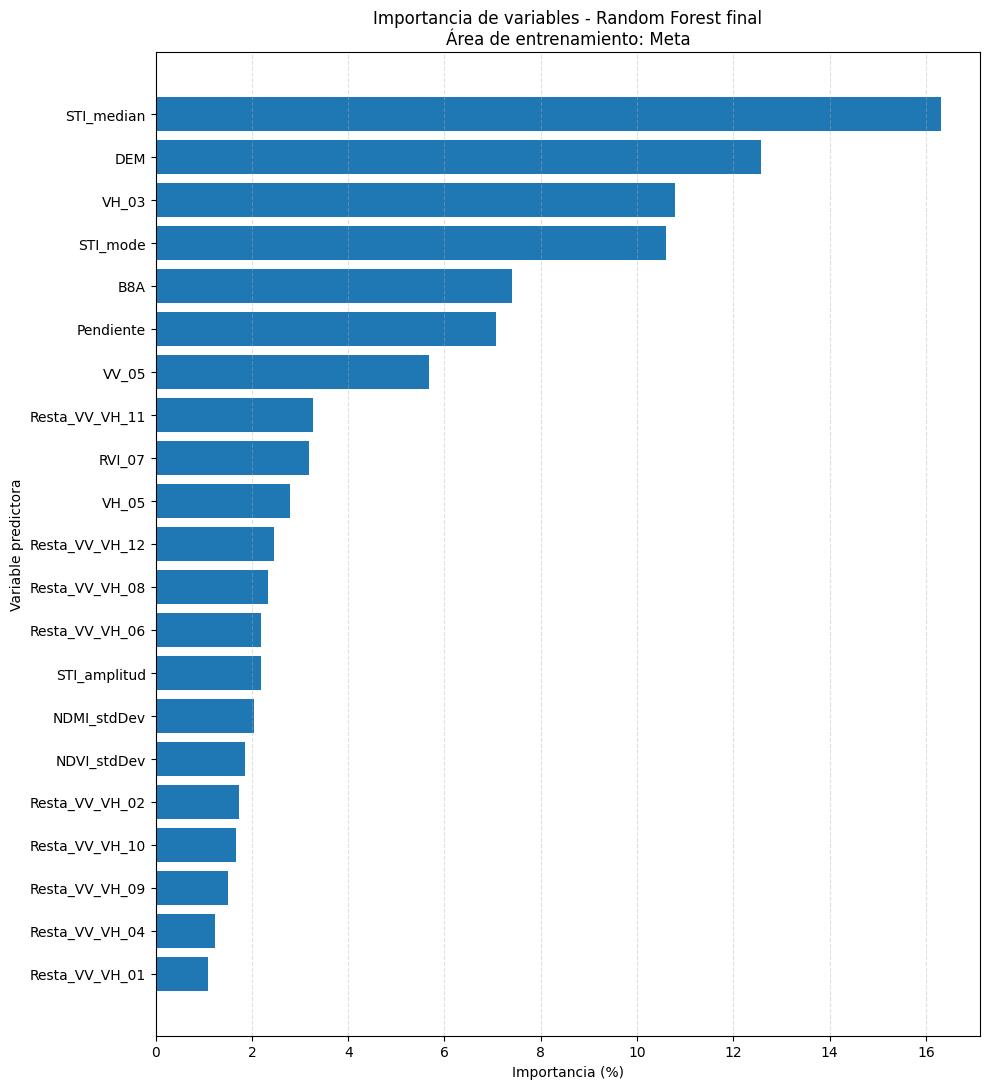

In [ ]:
# ============================================================
# GRÁFICO DE IMPORTANCIA DE VARIABLES
# ============================================================

import matplotlib.pyplot as plt

# Ordenar para gráfico horizontal
imp_plot = importancias_finales.sort_values(
    'Importancia_%',
    ascending=True
)

plt.figure(figsize=(10, 11))

plt.barh(
    imp_plot['Variable'],
    imp_plot['Importancia_%']
)

plt.xlabel('Importancia (%)')
plt.ylabel('Variable predictora')

plt.title(
    'Importancia de variables - Random Forest final\n'
    'Área de entrenamiento: Meta'
)

plt.grid(
    axis='x',
    linestyle='--',
    alpha=0.4
)

plt.tight_layout()
plt.show()

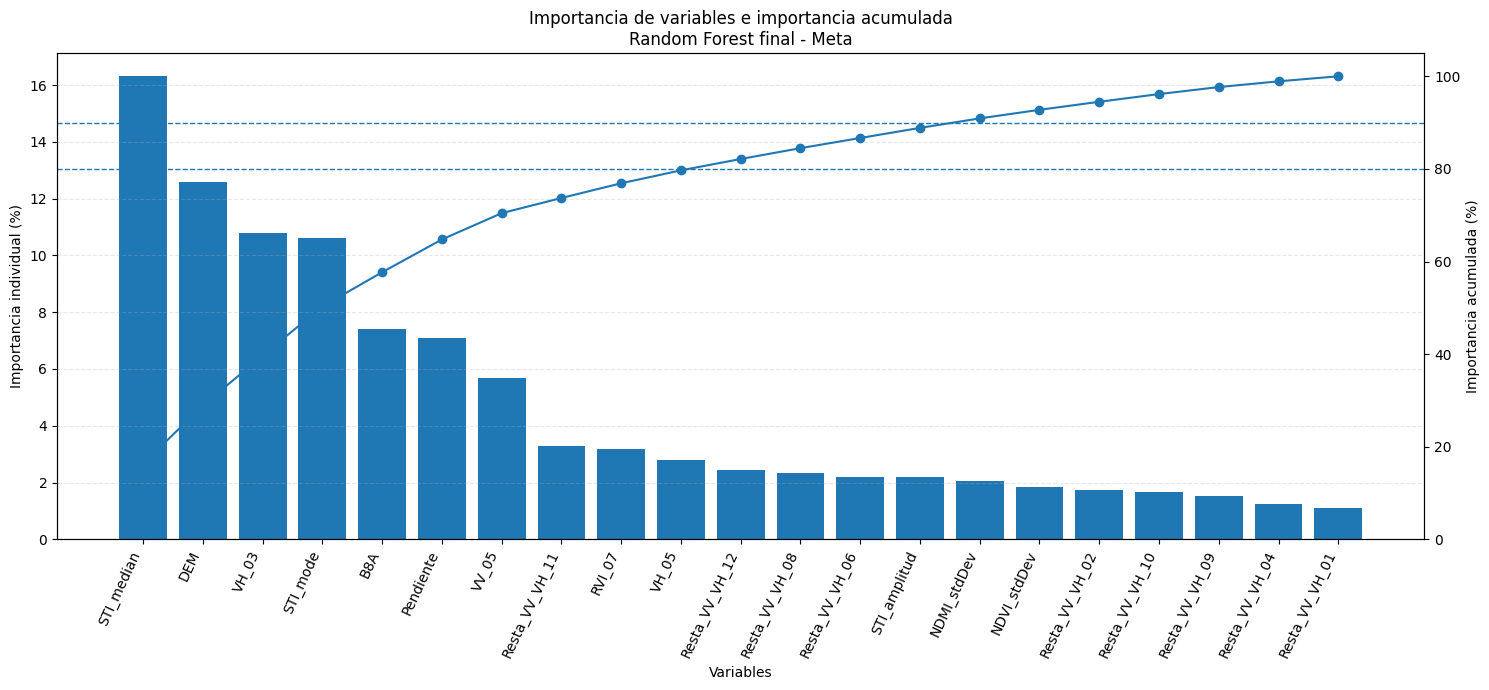

In [ ]:
# ============================================================
# IMPORTANCIA ACUMULADA
# RANDOM FOREST FINAL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Datos ordenados de mayor a menor
imp_pareto = importancias_finales.copy()

x = np.arange(len(imp_pareto))

# ------------------------------------------------------------
# Crear gráfico
# ------------------------------------------------------------

fig, ax1 = plt.subplots(figsize=(15, 7))

# Importancia individual
ax1.bar(
    x,
    imp_pareto['Importancia_%']
)

ax1.set_xlabel('Variables')
ax1.set_ylabel('Importancia individual (%)')

ax1.set_xticks(x)
ax1.set_xticklabels(
    imp_pareto['Variable'],
    rotation=65,
    ha='right'
)

ax1.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

# ------------------------------------------------------------
# Eje secundario: importancia acumulada
# ------------------------------------------------------------

ax2 = ax1.twinx()

ax2.plot(
    x,
    imp_pareto['Acumulada_%'],
    marker='o'
)

ax2.set_ylabel('Importancia acumulada (%)')
ax2.set_ylim(0, 105)

# Líneas de referencia
ax2.axhline(
    80,
    linestyle='--',
    linewidth=1
)

ax2.axhline(
    90,
    linestyle='--',
    linewidth=1
)

plt.title(
    'Importancia de variables e importancia acumulada\n'
    'Random Forest final - Meta'
)

fig.tight_layout()
plt.show()

In [ ]:
# ============================================================
# VARIABLES NECESARIAS PARA ALCANZAR 80 % Y 90 %
# DE LA IMPORTANCIA ACUMULADA
# ============================================================

n_80 = (
    importancias_finales['Acumulada_%']
    .lt(80)
    .sum() + 1
)

n_90 = (
    importancias_finales['Acumulada_%']
    .lt(90)
    .sum() + 1
)

print(
    f"Variables necesarias para alcanzar "
    f"aproximadamente el 80 % de importancia: {n_80}"
)

print(
    f"Variables necesarias para alcanzar "
    f"aproximadamente el 90 % de importancia: {n_90}"
)

print("\nVariables que concentran aproximadamente el 80 %:")
print(
    importancias_finales
    .head(n_80)[['Variable', 'Importancia_%', 'Acumulada_%']]
    .to_string(index=False)
)

Variables necesarias para alcanzar aproximadamente el 80 % de importancia: 11
Variables necesarias para alcanzar aproximadamente el 90 % de importancia: 15

Variables que concentran aproximadamente el 80 %:
      Variable  Importancia_%  Acumulada_%
    STI_median      16.308879    16.308879
           DEM      12.583151    28.892030
         VH_03      10.787267    39.679297
      STI_mode      10.605246    50.284543
           B8A       7.400010    57.684553
     Pendiente       7.074613    64.759167
         VV_05       5.678971    70.438137
Resta_VV_VH_11       3.278017    73.716154
        RVI_07       3.176233    76.892387
         VH_05       2.791627    79.684014
Resta_VV_VH_12       2.451805    82.135819


#**5. Validación del modelo**

## 5.1 Seleccionar las variables finales en Cesar<br>




Este bloque no reconstruye el stack. Solo selecciona del apilado_cesar ya existente las mismas variables que quedaron finalmente en el modelo de Meta.

In [ ]:
# ============================================================
# SELECCIONAR VARIABLES FINALES - CESAR
# ============================================================

apilado_cesar_reducido = (
    apilado_cesar
    .select(variables_finales)
)

print(
    "Número de variables finales:",
    len(variables_finales)
)

print(
    "Número de bandas seleccionadas en Cesar:",
    apilado_cesar_reducido
    .bandNames()
    .size()
    .getInfo()
)

print(
    "¿Coinciden variables y orden?:",
    apilado_cesar_reducido
    .bandNames()
    .getInfo()
    == variables_finales
)

Número de variables finales: 22
Número de bandas seleccionadas en Cesar: 22
¿Coinciden variables y orden?: True


## 5.2 Clasificar Cesar con el modelo entrenado en Meta

El clasificador no se vuelve a entrenar. Se aplica directamente el modelo final de Meta sobre Cesar.

In [ ]:
# ============================================================
# CLASIFICAR CESAR
# MODELO ENTRENADO EXCLUSIVAMENTE EN META
# ============================================================

clasificacion_cesar = (
    apilado_cesar_reducido
    .classify(classifier_meta)
    .rename('Predicted')
    .toByte()
)

print(
    "Clasificación de Cesar generada correctamente."
)

Clasificación de Cesar generada correctamente.


## 5.3 Preparar los polígonos independientes de validación

Primero asignamos un identificador único a cada polígono. Este poly_id permitirá agrupar después las predicciones para calcular la moda.

In [ ]:
# ============================================================
# ASIGNAR poly_id A LOS POLÍGONOS DE VALIDACIÓN
# ============================================================

# CARGAR MUESTRAS DE VALIDACIÓN DESDE LOS ASSETS
# (Utilizando el ID de asset correspondiente al AOI o sus muestras específicas)
asset_id_validacion = "projects/proyectogradolc/assets/MuestrasValidacion"
MuestrasValidacion = ee.FeatureCollection(asset_id_validacion)

n_poligonos_cesar = (
    MuestrasValidacion
    .size()
)

lista_cesar = (
    MuestrasValidacion
    .toList(n_poligonos_cesar)
)

indices_cesar = ee.List.sequence(
    0,
    n_poligonos_cesar.subtract(1)
)


def asignar_poly_id_cesar(i):

    feature = ee.Feature(
        lista_cesar.get(i)
    )

    return feature.set(
        'poly_id',
        ee.Number(i).add(1)
    )


MuestrasValidacion_id = ee.FeatureCollection(
    indices_cesar.map(
        asignar_poly_id_cesar
    )
)

print(
    "Polígonos de validación con poly_id:",
    MuestrasValidacion_id.size().getInfo()
)

Polígonos de validación con poly_id: 215


## 5.4 Aplicar el mismo buffer interno utilizado en Meta

Eliminamos 20 m del borde de los polígonos para reducir píxeles mixtos y efectos de borde.

In [ ]:
# ============================================================
# BUFFER INTERNO DE 20 m
# POLÍGONOS DE VALIDACIÓN - CESAR
# ============================================================

def crear_interior_cesar(feature):

    geom_interior = (
        feature
        .geometry()
        .buffer(-20)
    )

    return (
        ee.Feature(geom_interior)
        .copyProperties(feature)
        .set(
            'area_interior',
            geom_interior.area()
        )
    )


MuestrasValidacion_interior = (
    MuestrasValidacion_id
    .map(crear_interior_cesar)
    .filter(
        ee.Filter.gt(
            'area_interior',
            0
        )
    )
)

print(
    "Polígonos originales:",
    MuestrasValidacion_id.size().getInfo()
)

print(
    "Polígonos válidos después del buffer:",
    MuestrasValidacion_interior.size().getInfo()
)

Polígonos originales: 215
Polígonos válidos después del buffer: 199


## 5.5 Extraer máximo 30 píxeles interiores por polígono

Este procedimiento es equivalente al utilizado en Meta. De esta manera, un polígono grande no domina la validación por aportar miles de píxeles.

In [ ]:
# ============================================================
# MUESTREO DE VALIDACIÓN - CESAR
# ============================================================

N_PIXELES_VALIDACION = 30

def muestrear_poligono_cesar(feature):

    muestras = (
        clasificacion_cesar
        .sample(
            region=feature.geometry(),
            scale=20,
            numPixels=N_PIXELES_VALIDACION,
            seed=42,
            geometries=False,
            tileScale=4
        )
    )

    return muestras.map(
        lambda pixel: pixel.set({
            'Classvalue': feature.get('Classvalue'),
            'Classname': feature.get('Classname'),
            'poly_id': feature.get('poly_id')
        })
    )


validacion_cesar = (
    MuestrasValidacion_interior
    .map(muestrear_poligono_cesar)
    .flatten()
)

print(
    "Número total de píxeles extraídos:",
    validacion_cesar.size().getInfo()
)

Número total de píxeles extraídos: 5477


## 5.6 Validación espacial independiente — nivel de píxel

### 5.6.1 Convertir la validación a DataFrame

In [ ]:
# ============================================================
# DATAFRAME DE VALIDACIÓN
# NIVEL DE PÍXEL - CESAR
# ============================================================

df_validacion_cesar = geemap.ee_to_df(
    validacion_cesar
)

# Verificar qué columnas realmente existen en el DataFrame
columnas_disponibles = df_validacion_cesar.columns.tolist()
print("Columnas disponibles en GEE:", columnas_disponibles)

# Asegurar la existencia de las columnas requeridas asignando NaN si no existen
for col in ['Classvalue', 'Classname', 'Predicted', 'poly_id']:
    if col not in df_validacion_cesar.columns:
        df_validacion_cesar[col] = np.nan

df_validacion_cesar = (
    df_validacion_cesar[
        [
            'Classvalue',
            'Classname',
            'Predicted',
            'poly_id'
        ]
    ]
    .dropna(subset=['Predicted', 'poly_id']) # Evitar botar todo si Classvalue/Classname son nulos
    .copy()
)

# Rellenar valores nulos si Classvalue está vacío, para evitar errores al convertir a entero
if df_validacion_cesar['Classvalue'].isna().all():
    print("\nADVERTENCIA: 'Classvalue' no existe en el asset de validación de Cesar.")
    # Como alternativa, podemos asignar temporalmente la clase predicha o un valor por defecto
    df_validacion_cesar['Classvalue'] = df_validacion_cesar['Predicted']

df_validacion_cesar['Classvalue'] = (
    pd.to_numeric(
        df_validacion_cesar['Classvalue']
    )
    .fillna(0)
    .astype(int)
)

df_validacion_cesar['Predicted'] = (
    pd.to_numeric(
        df_validacion_cesar['Predicted']
    )
    .fillna(0)
    .astype(int)
)

df_validacion_cesar['poly_id'] = (
    pd.to_numeric(
        df_validacion_cesar['poly_id']
    )
    .fillna(0)
    .astype(int)
)

y_true_cesar = (
    df_validacion_cesar[
        'Classvalue'
    ]
)

y_pred_cesar = (
    df_validacion_cesar[
        'Predicted'
    ]
)

print(
    "Observaciones válidas:",
    len(df_validacion_cesar)
)

print(
    "Número de polígonos evaluados:",
    df_validacion_cesar[
        'poly_id'
    ].nunique()
)

Columnas disponibles en GEE: ['Classname', 'Classvalue', 'Predicted', 'poly_id']
Observaciones válidas: 5477
Número de polígonos evaluados: 198


In [ ]:
# ============================================================
# DEFINIR CLASES PRESENTES EN LA VALIDACIÓN - CESAR
# ============================================================

clases_cesar = sorted(
    set(y_true_cesar.unique())
    | set(y_pred_cesar.unique())
)

print(
    "Clases detectadas en la validación:",
    clases_cesar
)

Clases detectadas en la validación: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [ ]:
# ============================================================
# NOMBRES DE CLASES - CESAR
# ============================================================

nombres_clases_dict = {
    1: '1 - Cultivos Permanentes - Palma de Aceite',
    2: '2 - Superficies de Agua',
    3: '3 - Territorios Agricolas',
    4: '4 - Bosques y áreas seminaturales',
    5: '5 - Territorios Artificializados'
}

nombres_clases_cesar = [
    nombres_clases_dict[c]
    for c in clases_cesar
]

### 5.6.2 Métricas globales a nivel de píxel

In [ ]:
# ============================================================
# MÉTRICAS GLOBALES
# NIVEL DE PÍXEL - CESAR
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt


accuracy_cesar = accuracy_score(
    y_true_cesar,
    y_pred_cesar
)

balanced_accuracy_cesar = balanced_accuracy_score(
    y_true_cesar,
    y_pred_cesar
)

f1_macro_cesar = f1_score(
    y_true_cesar,
    y_pred_cesar,
    average='macro'
)

kappa_cesar = cohen_kappa_score(
    y_true_cesar,
    y_pred_cesar
)

mcc_cesar = matthews_corrcoef(
    y_true_cesar,
    y_pred_cesar
)


print(
    "VALIDACIÓN ESPACIAL INDEPENDIENTE - CESAR"
)

print(
    "NIVEL DE PÍXEL"
)

print(
    "=========================================="
)

print(
    f"Accuracy          : {accuracy_cesar:.4f}"
)

print(
    f"Balanced Accuracy : {balanced_accuracy_cesar:.4f}"
)

print(
    f"F1 macro          : {f1_macro_cesar:.4f}"
)

print(
    f"Kappa             : {kappa_cesar:.4f}"
)

print(
    f"MCC               : {mcc_cesar:.4f}"
)

VALIDACIÓN ESPACIAL INDEPENDIENTE - CESAR
NIVEL DE PÍXEL
Accuracy          : 0.7898
Balanced Accuracy : 0.8187
F1 macro          : 0.8039
Kappa             : 0.7052
MCC               : 0.7139


### 5.6.3 Reporte por clase a nivel de píxel

In [ ]:
# ============================================================
# REPORTE POR CLASE
# NIVEL DE PÍXEL - CESAR
# ============================================================

print(
    classification_report(
        y_true_cesar,
        y_pred_cesar,
        labels=clases_cesar,
        target_names=nombres_clases_cesar,
        digits=4,
        zero_division=0
    )
)

                                            precision    recall  f1-score   support

1 - Cultivos Permanentes - Palma de Aceite     0.9963    0.9628    0.9793      1128
                   2 - Superficies de Agua     1.0000    0.9302    0.9638       315
                 3 - Territorios Agricolas     0.8238    0.7310    0.7747      2610
         4 - Bosques y áreas seminaturales     0.8326    0.5445    0.6584       731
          5 - Territorios Artificializados     0.4931    0.9250    0.6433       693

                                  accuracy                         0.7898      5477
                                 macro avg     0.8292    0.8187    0.8039      5477
                              weighted avg     0.8288    0.7898    0.7955      5477



### 5.6.4 Matriz de confusión a nivel de píxel

In [ ]:
# ============================================================
# MATRIZ DE CONFUSIÓN
# NIVEL DE PÍXEL - CESAR
# ============================================================

cm_cesar = confusion_matrix(
    y_true_cesar,
    y_pred_cesar,
    labels=clases_cesar
)

cm_cesar_df = pd.DataFrame(
    cm_cesar,
    index=[
        f"Real {nombres_clases_dict[c]}"
        for c in clases_cesar
    ],
    columns=[
        f"Pred {nombres_clases_dict[c]}"
        for c in clases_cesar
    ]
)

display(
    cm_cesar_df
)

,Pred 1 - Cultivos Permanentes - Palma de Aceite,Pred 2 - Superficies de Agua,Pred 3 - Territorios Agricolas,Pred 4 - Bosques y áreas seminaturales,Pred 5 - Territorios Artificializados
Real 1 - Cultivos Permanentes - Palma de Aceite,1086,0,6,35,1
Real 2 - Superficies de Agua,0,293,22,0,0
Real 3 - Territorios Agricolas,1,0,1908,45,656
Real 4 - Bosques y áreas seminaturales,3,0,328,398,2
Real 5 - Territorios Artificializados,0,0,52,0,641


### 5.6.5 Matriz de confusión normalizada

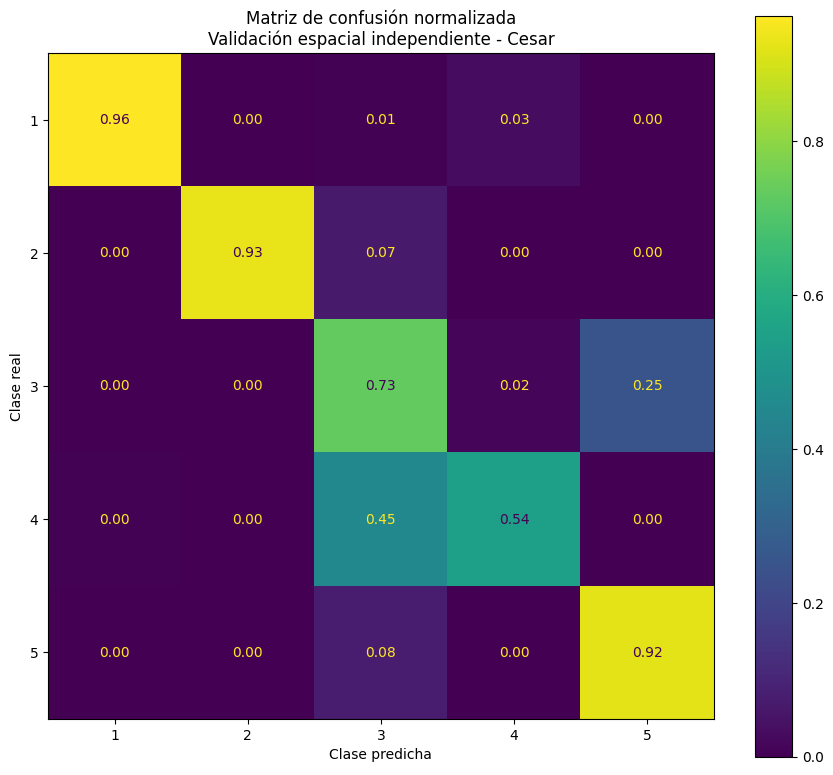

In [ ]:
# ============================================================
# MATRIZ DE CONFUSIÓN NORMALIZADA
# NIVEL DE PÍXEL - CESAR
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 8)
)

ConfusionMatrixDisplay.from_predictions(
    y_true_cesar,
    y_pred_cesar,
    labels=clases_cesar,
    display_labels=clases_cesar,
    normalize='true',
    values_format='.2f',
    ax=ax
)

plt.title(
    'Matriz de confusión normalizada\n'
    'Validación espacial independiente - Cesar'
)

plt.xlabel(
    'Clase predicha'
)

plt.ylabel(
    'Clase real'
)

plt.tight_layout()
plt.show()

## 5.7 Validación espacial independiente — nivel de polígono

### 5.7.1 Agrupar las predicciones por poly_id

In [ ]:
# ============================================================
# AGRUPAR PREDICCIONES POR POLÍGONO
# CESAR
# ============================================================

def moda_predicciones(serie):

    return (
        serie
        .value_counts()
        .idxmax()
    )


df_cesar_poly = (
    df_validacion_cesar
    .groupby(
        'poly_id'
    )
    .agg(
        Classvalue=(
            'Classvalue',
            'first'
        ),

        Classname=(
            'Classname',
            'first'
        ),

        Predicted_poly=(
            'Predicted',
            moda_predicciones
        ),

        N_pixeles=(
            'Predicted',
            'size'
        )
    )
    .reset_index()
)


print(
    "Número de polígonos evaluados:",
    len(df_cesar_poly)
)

display(
    df_cesar_poly.head()
)

Número de polígonos evaluados: 198


,poly_id,Classvalue,Classname,Predicted_poly,N_pixeles
0,1,1,Cultivos Permanentes - Palma de Aceite,1,36
1,2,1,Cultivos Permanentes - Palma de Aceite,1,27
2,3,1,Cultivos Permanentes - Palma de Aceite,1,35
3,4,1,Cultivos Permanentes - Palma de Aceite,1,29
4,5,1,Cultivos Permanentes - Palma de Aceite,1,27


### 5.7.2 Preparar clases reales y predichas por polígono

In [ ]:
# ============================================================
# VARIABLES DE VALIDACIÓN
# NIVEL DE POLÍGONO - CESAR
# ============================================================

y_true_cesar_poly = (
    df_cesar_poly[
        'Classvalue'
    ]
    .astype(int)
)

y_pred_cesar_poly = (
    df_cesar_poly[
        'Predicted_poly'
    ]
    .astype(int)
)


print(
    "Distribución real por polígono:"
)

print(
    y_true_cesar_poly
    .value_counts()
    .sort_index()
)


print(
    "\nDistribución predicha por polígono:"
)

print(
    y_pred_cesar_poly
    .value_counts()
    .sort_index()
)

Distribución real por polígono:
Classvalue
1    37
2    14
3    94
4    25
5    28
Name: count, dtype: int64

Distribución predicha por polígono:
Predicted_poly
1    37
2    14
3    84
4    15
5    48
Name: count, dtype: int64


### 5.7.3 Métricas globales a nivel de polígono

In [ ]:
# ============================================================
# MÉTRICAS GLOBALES
# NIVEL DE POLÍGONO - CESAR
# ============================================================

accuracy_cesar_poly = accuracy_score(
    y_true_cesar_poly,
    y_pred_cesar_poly
)

balanced_accuracy_cesar_poly = balanced_accuracy_score(
    y_true_cesar_poly,
    y_pred_cesar_poly
)

f1_macro_cesar_poly = f1_score(
    y_true_cesar_poly,
    y_pred_cesar_poly,
    average='macro'
)

kappa_cesar_poly = cohen_kappa_score(
    y_true_cesar_poly,
    y_pred_cesar_poly
)

mcc_cesar_poly = matthews_corrcoef(
    y_true_cesar_poly,
    y_pred_cesar_poly
)


print(
    "VALIDACIÓN ESPACIAL INDEPENDIENTE - CESAR"
)

print(
    "NIVEL DE POLÍGONO"
)

print(
    "=========================================="
)

print(
    f"Accuracy          : {accuracy_cesar_poly:.4f}"
)

print(
    f"Balanced Accuracy : {balanced_accuracy_cesar_poly:.4f}"
)

print(
    f"F1 macro          : {f1_macro_cesar_poly:.4f}"
)

print(
    f"Kappa             : {kappa_cesar_poly:.4f}"
)

print(
    f"MCC               : {mcc_cesar_poly:.4f}"
)

VALIDACIÓN ESPACIAL INDEPENDIENTE - CESAR
NIVEL DE POLÍGONO
Accuracy          : 0.8283
Balanced Accuracy : 0.8580
F1 macro          : 0.8439
Kappa             : 0.7598
MCC               : 0.7681


### 5.7.4 Reporte por clase a nivel de polígono

In [ ]:
# ============================================================
# CLASES PRESENTES - NIVEL DE POLÍGONO
# ============================================================

clases_cesar_poly = sorted(
    set(y_true_cesar_poly.unique())
    | set(y_pred_cesar_poly.unique())
)

nombres_clases_cesar_poly = [
    nombres_clases_dict[c]
    for c in clases_cesar_poly
]

In [ ]:
print(
    classification_report(
        y_true_cesar_poly,
        y_pred_cesar_poly,
        labels=clases_cesar_poly,
        target_names=nombres_clases_cesar_poly,
        digits=4,
        zero_division=0
    )
)

                                            precision    recall  f1-score   support

1 - Cultivos Permanentes - Palma de Aceite     1.0000    1.0000    1.0000        37
                   2 - Superficies de Agua     1.0000    1.0000    1.0000        14
                 3 - Territorios Agricolas     0.8571    0.7660    0.8090        94
         4 - Bosques y áreas seminaturales     0.9333    0.5600    0.7000        25
          5 - Territorios Artificializados     0.5625    0.9643    0.7105        28

                                  accuracy                         0.8283       198
                                 macro avg     0.8706    0.8580    0.8439       198
                              weighted avg     0.8619    0.8283    0.8305       198



### 5.7.5 Matriz de confusión a nivel de polígono

In [ ]:
# ============================================================
# MATRIZ DE CONFUSIÓN
# NIVEL DE POLÍGONO - CESAR
# ============================================================

cm_cesar_poly = confusion_matrix(
    y_true_cesar_poly,
    y_pred_cesar_poly,
    labels=clases_cesar_poly
)

cm_cesar_poly_df = pd.DataFrame(
    cm_cesar_poly,
    index=[
        f"Real {nombres_clases_dict[c]}"
        for c in clases_cesar_poly
    ],
    columns=[
        f"Pred {nombres_clases_dict[c]}"
        for c in clases_cesar_poly
    ]
)

display(
    cm_cesar_poly_df
)

,Pred 1 - Cultivos Permanentes - Palma de Aceite,Pred 2 - Superficies de Agua,Pred 3 - Territorios Agricolas,Pred 4 - Bosques y áreas seminaturales,Pred 5 - Territorios Artificializados
Real 1 - Cultivos Permanentes - Palma de Aceite,37,0,0,0,0
Real 2 - Superficies de Agua,0,14,0,0,0
Real 3 - Territorios Agricolas,0,0,72,1,21
Real 4 - Bosques y áreas seminaturales,0,0,11,14,0
Real 5 - Territorios Artificializados,0,0,1,0,27


## 5.8 Comparación entre las dos escalas de validación

In [ ]:
# ============================================================
# COMPARACIÓN DE ESCALAS DE VALIDACIÓN
# CESAR
# ============================================================

comparacion_cesar = pd.DataFrame({

    'Metrica': [
        'Accuracy',
        'Balanced Accuracy',
        'F1 macro',
        'Kappa',
        'MCC'
    ],

    'Pixel': [
        accuracy_cesar,
        balanced_accuracy_cesar,
        f1_macro_cesar,
        kappa_cesar,
        mcc_cesar
    ],

    'Poligono': [
        accuracy_cesar_poly,
        balanced_accuracy_cesar_poly,
        f1_macro_cesar_poly,
        kappa_cesar_poly,
        mcc_cesar_poly
    ]
})


display(
    comparacion_cesar
    .round(4)
)

,Metrica,Pixel,Poligono
0,Accuracy,0.7898,0.8283
1,Balanced Accuracy,0.8187,0.8580
2,F1 macro,0.8039,0.8439
3,Kappa,0.7052,0.7598
4,MCC,0.7139,0.7681


## 5.9 Mapa clasificado final — Cesar

### 5.9.1 Verificar las clases presentes

In [ ]:
# ============================================================
# VISUALIZACIÓN DE LA CLASIFICACIÓN - CESAR
# Clasificación + AOI + imagen RGB de referencia
# ============================================================

import geemap


# ------------------------------------------------------------
# Paleta de las cinco clases
# ------------------------------------------------------------

palette_clases = [
    'F4A261',  # 1 - Cultivos Permanentes - Palma de Aceite
    '2A9DF4',  # 2 - Superficies de Agua
    'F6D55C',  # 3 - Territorios Agricolas
    '2E8B57',  # 4 - Bosques y áreas seminaturales
    'D62828'   # 5 - Territorios Artificializados
]


vis_clasificacion = {
    'min': 1,
    'max': 5,
    'palette': palette_clases
}


# ------------------------------------------------------------
# Crear mapa
# ------------------------------------------------------------

Map_Cesar_RF = geemap.Map()

Map_Cesar_RF.centerObject(
    AOI_Cesar,
    10
)

Map_Cesar_RF.add_basemap(
    'SATELLITE'
)


# ------------------------------------------------------------
# Imagen RGB Sentinel-2 de referencia
# Se deja apagada inicialmente
# ------------------------------------------------------------

rgb_cesar = apilado_cesar.select(
    [
        'B4',
        'B3',
        'B2'
    ]
)

vis_rgb = {
    'min': 0,
    'max': 3000,
    'gamma': 1.2
}

Map_Cesar_RF.addLayer(
    rgb_cesar.clip(
        AOI_Cesar
    ),
    vis_rgb,
    'RGB Sentinel-2 - Cesar',
    False
)


# ------------------------------------------------------------
# Clasificación Random Forest
# ------------------------------------------------------------

Map_Cesar_RF.addLayer(
    clasificacion_cesar,
    vis_clasificacion,
    'Clasificación Random Forest - Cesar',
    True
)


# ------------------------------------------------------------
# Contorno del AOI de Cesar
# ------------------------------------------------------------

AOI_Cesar_contorno = (
    ee.FeatureCollection(
        AOI_Cesar
    )
    .style(
        color='FFFFFF',
        fillColor='00000000',
        width=3
    )
)

Map_Cesar_RF.addLayer(
    AOI_Cesar_contorno,
    {},
    'AOI Cesar',
    True
)


# ------------------------------------------------------------
# Leyenda
# ------------------------------------------------------------

legend_dict = {
    '1 - Cultivos Permanentes - Palma de Aceite': '#F4A261',
    '2 - Superficies de Agua': '#2A9DF4',
    '3 - Territorios Agricolas': '#F6D55C',
    '4 - Bosques y áreas seminaturales': '#2E8B57',
    '5 - Territorios Artificializados': '#D62828'
}

Map_Cesar_RF.add_legend(
    title='Coberturas',
    legend_dict=legend_dict
)


# ------------------------------------------------------------
# Control de capas
# ------------------------------------------------------------

Map_Cesar_RF.addLayerControl()


# ------------------------------------------------------------
# Mostrar mapa
# ------------------------------------------------------------

Map_Cesar_RF

Map(center=[9.758074137474429, -73.30118849241707], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# ============================================================
# EXPORTAR MAPA CLASIFICADO FINAL - CESAR
# GeoTIFF - Resolución 20 m
# ============================================================

task_export_cesar = ee.batch.Export.image.toDrive(
    image=clasificacion_cesar,
    description='Clasificacion_RF_Cesar_20m',
    folder='GEE_Tesis',
    fileNamePrefix='Clasificacion_RF_Cesar_20m',
    region=AOI_Cesar.geometry(),
    scale=20,
    maxPixels=1e13,
    fileFormat='GeoTIFF'
)

task_export_cesar.start()

print("Exportación iniciada correctamente.")
print("Archivo: Clasificacion_RF_Cesar_20m.tif")
print("Carpeta en Google Drive: GEE_Tesis")

Exportación iniciada correctamente.
Archivo: Clasificacion_RF_Cesar_20m.tif
Carpeta en Google Drive: GEE_Tesis
